# 03 · Las fuentes externas: qué cubre cada una, con qué calidad y qué se encontró con ella

## Pregunta y motivo

Este cuaderno inventaría las variables externas al hospital que podrían explicar por qué el triage de urgencias sube o baja. Para cada fuente responde qué cubre, desde cuándo, con qué rezago de publicación, con qué calidad medida y qué se encontró al cruzarla con el triage o con otras series del entorno.

El inventario importa porque el calendario solo dice *cuándo* suele subir el triage; el *por qué* de un pico o de una caída depende de factores externos (el clima, la enfermedad que circula en la ciudad, el estado de la red de aseguradores, las fiestas, las catástrofes), y cada uno llega al análisis a través de una serie que alguien midió, con sus huecos, sus cambios de registro y su retraso. Un cambio de registro se parece mucho a un efecto. Durante nueve meses el pluviómetro de La Nubia reportó 0 mm mientras llovía; esa serie fabricó sequías, y las sequías fabricaron «rupturas» de seco a lluvioso que parecían el mecanismo buscado. Por eso cada fuente se mira primero como serie, antes de usarla como variable.

Aquí no se correlaciona nada con el triage. Los hallazgos que se citan se midieron en los cuadernos 06 a 09, 12 a 14 y 17 a 21, y cada uno lleva su cuaderno de origen; la sección 8 los reúne en una tabla.

## Orden

1. Cobertura temporal de todas las fuentes.
2. Salud pública: SIVIGILA (microdatos) y Power BI del Instituto Nacional de Salud.
3. Clima: unificado, completo y el defecto del pluviómetro de La Nubia.
4. Seguridad: delitos de MinDefensa.
5. La red de salud: triage por asegurador, afiliación, BDUA y medidas de la Supersalud.
6. Ambiente y catástrofes: ENSO, sismos y desastres.
7. Calendario, eventos y fiestas de los municipios de Caldas.
8. Calidad, hallazgos, fuentes identificadas y no integradas, límites y conclusiones.

## De dónde salen los datos

El cuaderno no se conecta a ninguna base: lee archivos agregados del repositorio. Ninguno trae una columna de persona. Las direcciones y el detalle de cada fuente están en `calendarios/docs/`.

| Familia | Archivo | Quién lo publica | Origen | Cómo se rehace | Rezago |
|---|---|---|---|---|---|
| Triage (desenlace) | `salidas/triage_diario.parquet` | SES Hospital Universitario de Caldas | base del hospital, agregada por día | extracción de conteos agregados | al día de la extracción |
| Red de salud | `salidas/triage_entidad.parquet` | SES Hospital Universitario de Caldas | triage por día × hora × entidad administradora; los grupos salen de `extraccion/entidades.py` | extracción de conteos agregados | al día de la extracción |
| Vigilancia 995 y 998 | `calendarios/vigilancia_sivigila.csv.gz`, `…_instituciones.csv.gz` | Instituto Nacional de Salud (INS) | microdatos SIVIGILA, `https://portalsivigila.ins.gov.co/Microdatos/Datos_{AÑO}_{EVENTO}.xlsx` | `python calendarios/vigilancia/sivigila.py --eventos 995 998 --desde 2011` | ~8 meses |
| Vigilancia, eventos individuales | `calendarios/vigilancia_sivigila_eventos.csv.gz`, `…_eventos_censo.csv` | INS | los mismos microdatos | `python calendarios/vigilancia/eventos.py --sin-red` | ~8 meses |
| Vigilancia 2026 | `calendarios/vigilancia/powerbi/AAAA-MM-DD/` | INS | tablero Power BI «006 Vigilancia Rutinaria» y un tablero por evento; la clave se lee de la lista `MenuReporteNivel2` de `portalsivigila.ins.gov.co` | `python calendarios/vigilancia/powerbi.py` (congela la descarga del día) | ~7 días |
| Clima unificado | `calendarios/clima_unificado.csv.gz` | IDEAM; Aerocivil (METAR de La Nubia) vía Iowa Environmental Mesonet; Open-Meteo (ERA5); NASA POWER | sección 3 | `python calendarios/clima/clima_manizales.py` y `clima_unificado.py` | días |
| Clima completo | `calendarios/clima_completo.csv.gz` | Open-Meteo (ERA5) y NASA POWER | reanálisis en La Nubia desde 2010, con horas de sol, nubosidad, punto de rocío, déficit de presión de vapor y transiciones | `python calendarios/clima/clima_completo.py` | ~5 días |
| ENSO | `calendarios/enso_oni.csv` | NOAA, Climate Prediction Center | índice ONI, `https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt` | `python calendarios/clima/enso.py` | ~1 mes |
| Sismos | `calendarios/sismos_usgs.csv` | USGS | catálogo FDSN a 150 km de Manizales, `https://earthquake.usgs.gov/fdsnws/event/1/query` | `python calendarios/fenomenos/sismos_usgs.py` | minutos |
| Seguridad | `calendarios/seguridad_mindefensa.csv.gz` | Ministerio de Defensa Nacional (Policía) | `https://www.datos.gov.co/resource/<id>.json` | `python calendarios/seguridad/mindefensa.py` | 2-6 semanas |
| Afiliación por EPS | `calendarios/capturas/afiliacion/` | Ministerio de Salud | zips mensuales «Cifras de afiliación en salud», hoja `EPSMunicipio`; se guarda solo Caldas | captura semanal | ~1 mes |
| Afiliados por EPS y edad | `calendarios/capturas/bdua/` | ADRES, vía datos.gov.co (`tq4m-hmg2`, `d7a5-cnra`) | base única de afiliados, solo la foto del mes | captura semanal | ninguno, pero sin histórico |
| Medidas especiales | `calendarios/capturas/medidas/` | Superintendencia Nacional de Salud | Excel de EPS e IPS en medida preventiva, intervención o liquidación; se guarda una tabla limpia | captura semanal | ~1 semana; solo medidas vigentes |
| Calendario | `calendarios/calendario_Colombia.csv` | festivos de ley (librería `holidays`) y reglas propias | — | `python calendarios/calendario_colombia.py --inicio 2020-01-01 --fin 2026-12-31` | se conoce de antemano |
| Recesos escolares | `calendarios/calendario_escolar_manizales.csv` | Secretaría de Educación de Manizales y Ministerio de Educación | resoluciones anuales, con la URL de cada una | a mano | se conoce de antemano |
| Fiestas de Caldas | `calendarios/fiestas_caldas_2020_2026.csv` | alcaldías, Gobernación, Cultura de Caldas y prensa | una URL por fila | a mano | se conoce de antemano |
| Eventos, desastres, vigilancia manual | `calendarios/eventos_…csv`, `desastres_…csv`, `vigilancia_salud_…csv` | escritos a mano; cada fila con su `fuente_url` | prensa, Alcaldía, INS, IDEAM | a mano | — |

**Captura automática.** Varias fuentes publican solo el estado vigente y lo sobrescriben: la BDUA, el tablero de Power BI, los Excel de medidas de la Supersalud y las cifras mensuales de afiliación. Una tarea programada de Windows las guarda cada lunes a las 08:00 y solo conserva un archivo nuevo si cambió su huella (`calendarios/capturas.py`). La primera captura, del 2026-10-05, guardó la BDUA con corte del 2026-10-02, nueve Excel de medidas, catorce meses de afiliación y el ONI. Sin esta captura no existiría el historial de lo que se sabía cada semana, que es lo que permite evaluar un pronóstico con la información de su momento.

**Privacidad.** Los Excel del SIVIGILA traen nombre, teléfono y correo de quien notifica; se descartan en el mismo paso de lectura y el crudo está excluido del control de versiones. De los tableros de Power BI solo se piden medidas agregadas, y el programa rechaza cualquier columna de persona. De MinDefensa, solo sumas por día. Los Excel de medidas de la Supersalud nombran a los interventores: el original se guarda fuera del control de versiones y aquí solo se usa la tabla con entidad, resolución y fechas. El archivo por entidad trae nombres de aseguradoras, no de personas.

In [1]:
import sys, pathlib, warnings, json
from urllib.parse import urlparse
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ)); warnings.filterwarnings("ignore")
import re, glob
import numpy as np, pandas as pd
from matplotlib import pyplot as plt
import matplotlib.dates as mdates
from extraccion.entidades import clasificar

AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "savefig.facecolor": SUP,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True,
    "grid.color": "#e6e5e1", "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2,
    "ytick.color": TINTA2, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA,
    "font.size": 10, "legend.frameon": False})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

CAL = RAIZ / "calendarios"
PBI = CAL / "vigilancia" / "powerbi" / "2026-10-05"   # instantánea fija: las cifras del texto corresponden a esta captura

tri = pd.read_parquet(RAIZ / "salidas/triage_diario.parquet").assign(dia=lambda d: pd.to_datetime(d.dia))
ent = clasificar(pd.read_parquet(RAIZ / "salidas/triage_entidad.parquet"))
vig = pd.read_csv(CAL / "vigilancia_sivigila.csv.gz", parse_dates=["fecha_inicio_semana"])
eve = pd.read_csv(CAL / "vigilancia_sivigila_eventos.csv.gz", parse_dates=["fecha_inicio_semana"])
censo = pd.read_csv(CAL / "vigilancia_sivigila_eventos_censo.csv")
inst = pd.read_csv(CAL / "vigilancia_sivigila_instituciones.csv.gz", parse_dates=["fecha_inicio_semana"])
clima = pd.read_csv(CAL / "clima_unificado.csv.gz", parse_dates=["fecha"]).set_index("fecha")
seg = pd.read_csv(CAL / "seguridad_mindefensa.csv.gz", parse_dates=["fecha"]).set_index("fecha")
calc = pd.read_csv(CAL / "calendario_Colombia.csv", parse_dates=["fecha"]).set_index("fecha")
eventos = pd.read_csv(CAL / "eventos_manizales_2020_2026.csv")
desastres = pd.read_csv(CAL / "desastres_manizales_2020_2026.csv")
vman = pd.read_csv(CAL / "vigilancia_salud_manizales_caldas.csv")
pbi = {p.stem: pd.read_csv(p) for p in PBI.glob("*.csv")}
meta = json.load(open(PBI / "metadatos.json", encoding="utf-8"))
SES = 170010010301
oni = pd.read_csv(CAL / "enso_oni.csv", parse_dates=["fecha"])
sis = pd.read_csv(CAL / "sismos_usgs.csv", parse_dates=["fecha"])
fiestas = pd.read_csv(CAL / "fiestas_caldas_2020_2026.csv", parse_dates=["fecha_inicio", "fecha_fin"])
escolar = pd.read_csv(CAL / "calendario_escolar_manizales.csv", parse_dates=["fecha_inicio", "fecha_fin"])
cc = pd.read_csv(CAL / "clima_completo.csv.gz", parse_dates=["fecha"]).set_index("fecha")

# Afiliación mensual por EPS en Manizales (zips de MinSalud guardados por la captura semanal).
MESES_ES = {"ene": 1, "feb": 2, "mar": 3, "abr": 4, "may": 5, "jun": 6, "jul": 7, "ago": 8, "sep": 9, "oct": 10, "nov": 11, "dic": 12}
MAPA_EPS = {"NUEVA EPS": "Nueva EPS", "EPS SURA": "SURA", "SALUD TOTAL EPS": "Salud Total", "EPS SANITAS": "Sanitas"}
filas_af = []
for f in glob.glob(str(CAL / "capturas/afiliacion/*_caldas.csv.gz")):
    m = re.search(r"(ene|feb|mar|abr|may|jun|jul|ago|sep|oct|nov|dic)[a-z]*[-_]?(\d{4})", f.lower())
    mes_f = pd.Timestamp(int(m.group(2)), MESES_ES[m.group(1)], 1)
    d = pd.read_csv(f); e = d[d.hoja == "EPSMunicipio"].pivot(index="fila", columns="columna", values="valor")
    c_mun = next(c for c in e.columns if c.split("| ")[-1].upper() == "MUNICIPIO")
    c_eps = next(c for c in e.columns if c.split("| ")[-1].upper() == "EPS")
    e = e[e[c_mun].astype(str).str.upper().str.contains("MANIZALES")]
    c_af = [c for c in e.columns if c.split("| ")[-1].strip().upper().startswith("AFILIADOS")]
    for _, r in e.iterrows():
        filas_af.append({"mes": mes_f, "eps": r[c_eps], "afiliados": pd.to_numeric(r[c_af], errors="coerce").fillna(0).sum()})
AFIL = pd.DataFrame(filas_af).pivot_table(index="mes", columns="eps", values="afiliados", aggfunc="sum").sort_index()
bdua = {r: pd.read_csv(f) for r in ("contributivo", "subsidiado") for f in sorted(glob.glob(str(CAL / f"capturas/bdua/bdua_caldas_{r}_*.csv.gz")))[-1:]}

def inicio_semana_epi(anio, semana):
    """Domingo que abre la semana epidemiologica: la SE1 es la que contiene el 4 de enero."""
    d = pd.Timestamp(anio, 1, 4)
    return d - pd.Timedelta(days=(d.dayofweek + 1) % 7) + pd.Timedelta(weeks=int(semana) - 1)

def tramos(mascara):
    """Tramos contiguos de dias en True, como (inicio, duracion) para broken_barh."""
    m = mascara.astype(bool)
    grupo = (m != m.shift()).cumsum()
    return [(mdates.date2num(g.index[0]), len(g)) for _, g in m.groupby(grupo) if g.iloc[0]]

print(f"afiliación MinSalud en Manizales: {AFIL.index.min():%Y-%m} a {AFIL.index.max():%Y-%m} ({len(AFIL)} meses); BDUA, corte {bdua['contributivo'].corte_datos_gov.iloc[0]}")
print(f"triage diario: {tri.dia.min():%Y-%m-%d} a {tri.dia.max():%Y-%m-%d}; "
      f"por entidad: {ent.dia.min():%Y-%m-%d} a {ent.dia.max():%Y-%m-%d}")
print(f"instantanea Power BI: {PBI.name} (descargada {meta['descargado']}; refresco del INS del 006: "
      f"{meta['archivos']['rutinaria_manizales.csv']['refresco_ins']})")

afiliación MinSalud en Manizales: 2025-07 a 2026-08 (14 meses); BDUA, corte 2026-10-02
triage diario: 2020-01-01 a 2026-09-21; por entidad: 2020-01-01 a 2026-09-28
instantanea Power BI: 2026-10-05 (descargada 2026-10-05T10:42:36; refresco del INS del 006: 2026-10-03T22:04:56.187)


---
# 1. Cobertura temporal: qué hay y desde cuándo

Una barra por fuente, de 2010 a 2026. La franja gris es el periodo en que existe el triage. Las filas «días con pluviómetro» y «días con METAR» son las medidas **en tierra** que hay debajo del clima unificado: el consenso cubre todos los días, pero no todos los días tienen una medida real. En rojo, los días en que el pluviómetro de La Nubia reporta lecturas falsas (sección 3).

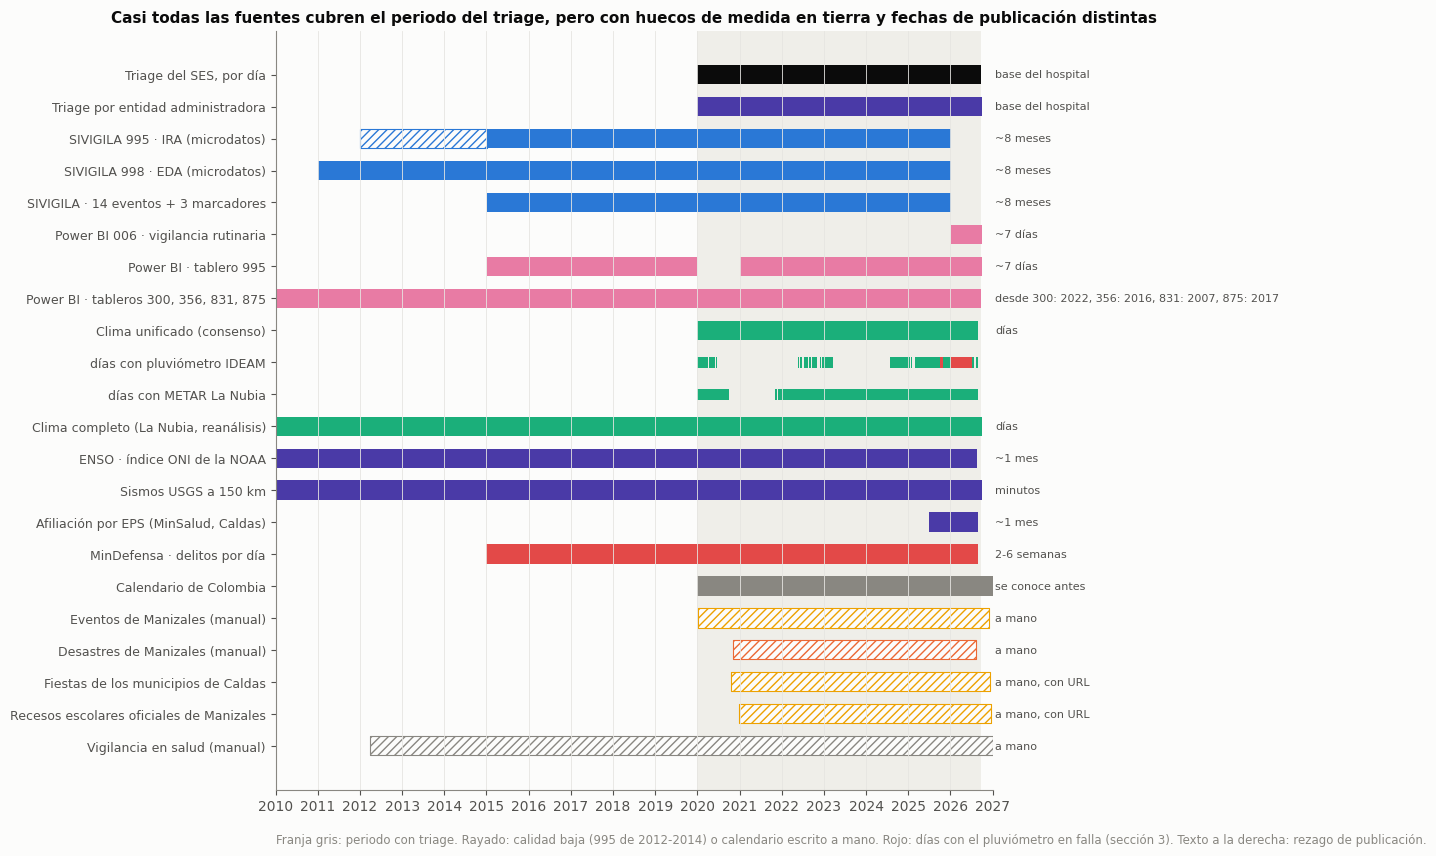

días con el pluviómetro en falla (pluviometro_fallido): 199, del 2025-10-05 al 2026-07-08; meses: ['2025-10', '2026-01', '2026-02', '2026-03', '2026-04', '2026-05', '2026-06', '2026-07']


,desde,hasta
fuente,,
"Triage del SES, por día",2020-01-01,2026-09-21
Triage por entidad administradora,2020-01-01,2026-09-28
SIVIGILA 995 · IRA (microdatos),2012-01-01,2026-01-03
SIVIGILA 998 · EDA (microdatos),2011-01-02,2026-01-03
SIVIGILA · 14 eventos + 3 marcadores,2015-01-04,2026-01-03
Power BI 006 · vigilancia rutinaria,2026-01-04,2026-10-03
Power BI · tablero 995,2015-01-04,2026-10-03
"Power BI · tableros 300, 356, 831, 875",2007-01-01,2026-09-26
Clima unificado (consenso),2020-01-01,2026-08-28


In [2]:
AN = lambda a, b=None: (pd.Timestamp(a), pd.Timestamp(b) if b else pd.Timestamp(a))
dias_clima = clima.index
filas = []   # (familia, etiqueta, color, [(ini, fin, estilo)], nota)
filas.append(("desenlace", "Triage del SES, por día", TINTA, [(tri.dia.min(), tri.dia.max(), "ok")], "base del hospital"))
filas.append(("red", "Triage por entidad administradora", VIOLETA, [(ent.dia.min(), ent.dia.max(), "ok")], "base del hospital"))

m995 = vig[(vig.ambito == "manizales") & (vig.evento == 995)]
m998 = vig[(vig.ambito == "manizales") & (vig.evento == 998)]
f995 = m995.groupby("anio").fecha_inicio_semana.agg(["min", "max"])
f998 = m998.groupby("anio").fecha_inicio_semana.agg(["min", "max"])
filas.append(("salud", "SIVIGILA 995 · IRA (microdatos)", AZUL,
              [(f995.loc[2012, "min"], f995.loc[2014, "max"] + pd.Timedelta(days=6), "baja"),
               (f995.loc[2015, "min"], f995.loc[2025, "max"] + pd.Timedelta(days=6), "ok")], "~8 meses"))
filas.append(("salud", "SIVIGILA 998 · EDA (microdatos)", AZUL,
              [(f998["min"].min(), f998["max"].max() + pd.Timedelta(days=6), "ok")], "~8 meses"))
fe = eve[eve.ambito == "manizales"].fecha_inicio_semana
filas.append(("salud", "SIVIGILA · 14 eventos + 3 marcadores", AZUL, [(fe.min(), fe.max() + pd.Timedelta(days=6), "ok")], "~8 meses"))
rut = pbi["rutinaria_manizales"]
filas.append(("salud", "Power BI 006 · vigilancia rutinaria", MAGENTA,
              [(inicio_semana_epi(2026, 1), inicio_semana_epi(2026, rut.semana.max()) + pd.Timedelta(days=6), "ok")], "~7 días"))
tb = pbi["ira_995_tablero"]; anios_tb = sorted(tb.anio.unique())
seg_tb, ini_ = [], anios_tb[0]
for a, b in zip(anios_tb, anios_tb[1:] + [None]):
    if b != a + 1:
        fin_ = inicio_semana_epi(a, tb[tb.anio == a].semana.max()) + pd.Timedelta(days=6)
        seg_tb.append((inicio_semana_epi(ini_, 1), fin_, "ok")); ini_ = b
filas.append(("salud", "Power BI · tablero 995", MAGENTA, seg_tb, "~7 días"))
inicio_ev = {k.split("_")[1]: int(v[v.casos > 0].anio.min()) for k, v in pbi.items() if k.startswith("evento_")}
filas.append(("salud", "Power BI · tableros 300, 356, 831, 875", MAGENTA,
              [(pd.Timestamp(min(inicio_ev.values()), 1, 1), pd.Timestamp("2026-09-26"), "ok")],
              "desde " + ", ".join(f"{k}: {v}" for k, v in sorted(inicio_ev.items()))))
filas.append(("clima", "Clima unificado (consenso)", AQUA, [(dias_clima.min(), dias_clima.max(), "ok")], "días"))
filas.append(("clima", "  días con pluviómetro IDEAM", AQUA, tramos(clima.precip_con_estacion.astype(bool)), "tramos"))
# Días con el pluviómetro en falla: los marca la columna pluviometro_fallido del clima unificado y no cuentan como días con pluviómetro.
FALLA = clima.pluviometro_fallido.astype(bool)
MESES_FALLA = [m.to_timestamp() for m in FALLA.groupby(clima.index.to_period("M")).sum()[lambda s: s > 0].index]
filas.append(("clima", "  días con METAR La Nubia", AQUA, tramos(clima.iem_tmedia_c.notna()), "tramos"))
filas.append(("clima", "Clima completo (La Nubia, reanálisis)", AQUA, [(cc.index.min(), cc.index.max(), "ok")], "días"))
filas.append(("ambiente", "ENSO · índice ONI de la NOAA", VIOLETA, [(oni.fecha.min(), oni.fecha.max(), "ok")], "~1 mes"))
filas.append(("ambiente", "Sismos USGS a 150 km", VIOLETA, [(sis.fecha.min(), sis.fecha.max(), "ok")], "minutos"))
filas.append(("red", "Afiliación por EPS (MinSalud, Caldas)", VIOLETA, [(AFIL.index.min(), AFIL.index.max() + pd.offsets.MonthEnd(0), "ok")], "~1 mes"))
filas.append(("seguridad", "MinDefensa · delitos por día", ROJO, [(seg.index.min(), seg.index.max(), "ok")], "2-6 semanas"))
filas.append(("calendario", "Calendario de Colombia", MUDO, [(calc.index.min(), calc.index.max(), "ok")], "se conoce antes"))
filas.append(("manual", "Eventos de Manizales (manual)", AMARILLO,
              [(pd.to_datetime(eventos.fecha_inicio).min(), pd.to_datetime(eventos.fecha_fin).max(), "manual")], "a mano"))
filas.append(("manual", "Desastres de Manizales (manual)", NARANJA,
              [(pd.to_datetime(desastres.fecha_inicio).min(), pd.to_datetime(desastres.fecha_fin).max(), "manual")], "a mano"))
filas.append(("manual", "Fiestas de los municipios de Caldas", AMARILLO, [(fiestas.fecha_inicio.min(), fiestas.fecha_fin.max(), "manual")], "a mano, con URL"))
filas.append(("manual", "Recesos escolares oficiales de Manizales", AMARILLO, [(escolar.fecha_inicio.min(), escolar.fecha_fin.max(), "manual")], "a mano, con URL"))
filas.append(("manual", "Vigilancia en salud (manual)", MUDO,
              [(pd.to_datetime(vman.fecha_inicio).min(), pd.to_datetime(vman.fecha_fin).max(), "manual")], "a mano"))

fig, ax = plt.subplots(figsize=(13, 8.6))
ax.axvspan(mdates.date2num(tri.dia.min()), mdates.date2num(tri.dia.max()), color="#efeee9", zorder=0, lw=0)
X0, X1 = mdates.date2num(pd.Timestamp("2010-01-01")), mdates.date2num(pd.Timestamp("2027-01-01"))
for i, (fam, etq, col, segs, nota) in enumerate(filas):
    y = len(filas) - i
    alto = 0.34 if etq.startswith("  ") else 0.6
    for s in segs:
        if nota == "tramos":
            ax.broken_barh([s], (y - alto / 2, alto), color=col, lw=0)
            continue
        ini, fin, est = s
        a, b = max(mdates.date2num(ini), X0), mdates.date2num(fin)
        estilo = dict(color=col, lw=0) if est == "ok" else dict(facecolor=SUP, edgecolor=col, hatch="////", lw=.8)
        ax.broken_barh([(a, b - a)], (y - alto / 2, alto), **estilo)
    if etq.strip() == "días con pluviómetro IDEAM":
        ax.broken_barh(tramos(FALLA), (y - alto / 2, alto), color=ROJO, lw=0)
    if nota != "tramos":
        ax.text(X1 + 20, y, nota, va="center", fontsize=8, color=TINTA2)
ax.set_yticks([len(filas) - i for i in range(len(filas))], [f[1] for f in filas], fontsize=9)
ax.set_xlim(X0, X1); ax.xaxis_date(); ax.xaxis.set_major_locator(mdates.YearLocator(1)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(axis="y", visible=False)
ax.set_title("Casi todas las fuentes cubren el periodo del triage, pero con huecos de medida en tierra y fechas de publicación distintas", fontsize=11)
ax.text(0, -.07, "Franja gris: periodo con triage. Rayado: calidad baja (995 de 2012-2014) o calendario escrito a mano. Rojo: días con el pluviómetro en falla (sección 3). Texto a la derecha: rezago de publicación.",
        transform=ax.transAxes, fontsize=8.5, color=MUDO)
plt.tight_layout(); plt.show()

tabla = pd.DataFrame([{"fuente": f[1].strip(), "desde": min(s[0] for s in f[3]) if f[4] != "tramos" else mdates.num2date(f[3][0][0]).date(),
                       "hasta": max(s[1] for s in f[3]) if f[4] != "tramos" else mdates.num2date(f[3][-1][0] + f[3][-1][1] - 1).date()}
                      for f in filas])
tabla["desde"] = pd.to_datetime(tabla.desde).dt.date; tabla["hasta"] = pd.to_datetime(tabla.hasta).dt.date
print(f"días con el pluviómetro en falla (pluviometro_fallido): {FALLA.sum()}, del {FALLA[FALLA].index.min():%Y-%m-%d} "
      f"al {FALLA[FALLA].index.max():%Y-%m-%d}; meses: {[f'{m:%Y-%m}' for m in MESES_FALLA]}")
tabla.set_index("fuente")

## Lectura

**Todo lo que se necesita cubre el periodo del triage desde 2020, con salvedades en el final de la serie y en la medida real.**

- **Cubren desde 2020:** el clima unificado y MinDefensa (ambos terminan a fines de agosto de 2026), el calendario, el ENSO, los sismos y el triage por asegurador (hasta el 2026-09-28).
- **Los microdatos del SIVIGILA terminan en la semana epidemiológica 53 de 2025** (2026-01-03). Para 2026 la vía es Power BI: dos instantáneas guardadas, la del 2026-09-28 y la del 2026-10-05, esta última con 39 semanas en el tablero 006.
- **El tablero 995 de Power BI no tiene 2020.** Tiene 2015-2019 y 2021-2026.
- **La afiliación por EPS de MinSalud empieza en julio de 2025** (14 meses). Los zips anteriores no están enlazados en la página, y de la BDUA solo existe la foto del mes.
- **El clima tiene menos medida real de lo que parece.** El pluviómetro IDEAM no tiene lecturas de agosto de 2020 a diciembre de 2021 ni de abril de 2023 a junio de 2024, y el METAR casi no tiene datos de octubre de 2020 a octubre de 2021. A eso se suman 199 días de lectura en falla, del 2025-10-05 al 2026-07-08.
- Los calendarios escritos a mano cubren 2020-2026, pero son **listas de fechas**, no series.

**Límite.** Una barra dice que hay archivo, no que el dato sea bueno. Para eso están las secciones 2 a 7 y la tabla de calidad de la sección 8.

---
# 2. Salud pública: el SIVIGILA del INS

## 2.1 Evento 995: consultas por IRA con su denominador

**Qué es.** Notificación **colectiva semanal** de cada institución (UPGD): consultas por infección respiratoria aguda (IRA) y por todas las causas, hospitalizaciones, UCI y muertes, en 7 grupos de edad. Sale de los RIPS. Es la única fuente de vigilancia con **denominador**.

- **Publica:** Instituto Nacional de Salud, `https://portalsivigila.ins.gov.co/Microdatos/Datos_{AÑO}_995.xlsx`.
- **Se rehace con** `python calendarios/vigilancia/sivigila.py --eventos 995 998 --desde 2011`.
- **Rezago: ~8 meses.** Los microdatos de 2025 salieron el 25 de agosto de 2026. Sirven para entrenar y medir, no para operar.
- **Cobertura:** 2012-2025, usable desde 2015.

La figura separa el numerador (IRA) del denominador (todas las causas) y cuenta cuántas instituciones de Manizales notifican.

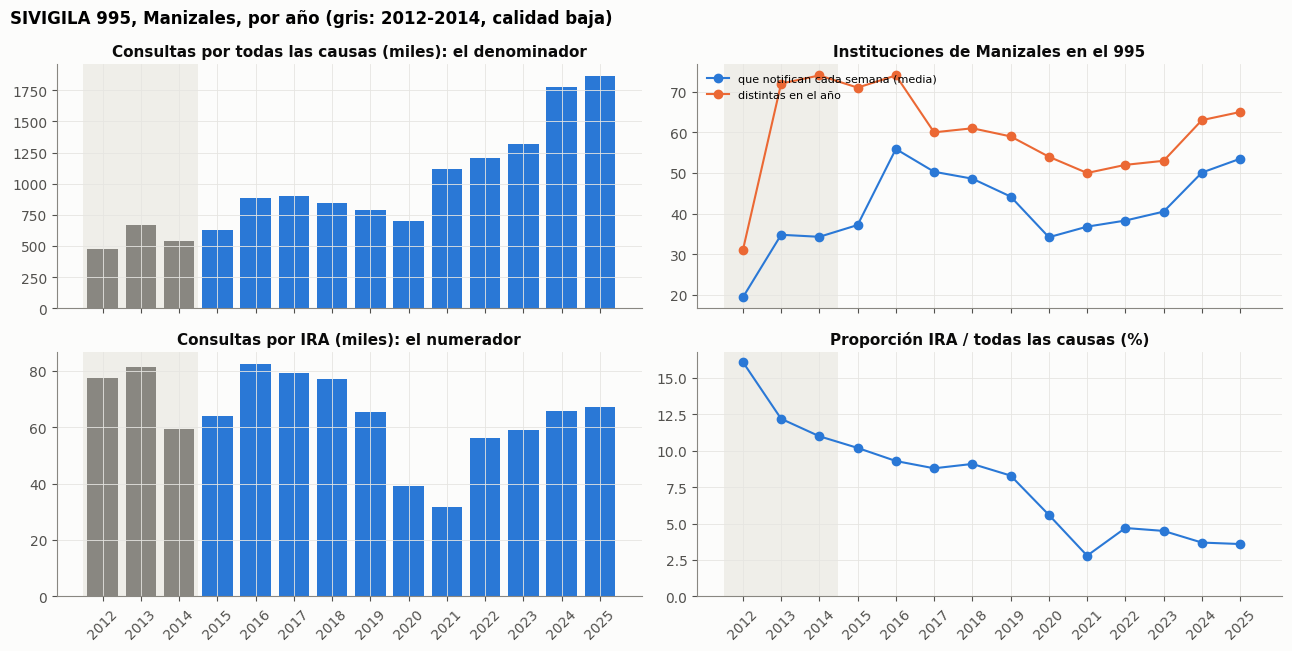

,consultas todas las causas,consultas IRA,% IRA,instituciones por semana,instituciones distintas,nuevas respecto del año anterior,% del denominador que es el SES
2012,479549.0,77435.0,16.1,19.4,31,NaN,13.3
2013,668816.0,81330.0,12.2,34.8,72,45.0,11.9
2014,542856.0,59487.0,11.0,34.3,74,13.0,11.1
2015,627569.0,64048.0,10.2,37.2,71,10.0,9.4
2016,886471.0,82486.0,9.3,55.9,74,15.0,6.8
2017,902920.0,79259.0,8.8,50.3,60,2.0,7.2
2018,848803.0,77002.0,9.1,48.6,61,5.0,6.3
2019,786067.0,65291.0,8.3,44.2,59,3.0,9.5
2020,700847.0,39261.0,5.6,34.2,54,1.0,7.1
2021,1121559.0,31648.0,2.8,36.8,50,0.0,6.1


In [3]:
todas = m995[m995.variable == "consultas_todas_causas_total"].groupby("anio").valor.sum()
ira = m995[m995.variable == "consultas_ira_total"].groupby("anio").valor.sum()
n_inst = m995[m995.variable == "n_instituciones_notificando"].groupby("anio").valor.mean()
i995 = inst[inst.evento == 995]
distintas = i995.groupby("anio").cod_upgd.nunique()
conj = i995.groupby("anio").cod_upgd.apply(set)
nuevas = pd.Series({a: len(conj[a] - conj[a - 1]) if a - 1 in conj.index else np.nan for a in conj.index})
ses = i995[i995.cod_upgd == SES].groupby("anio").consultas_todas_causas.sum()
A995 = pd.DataFrame({"consultas todas las causas": todas, "consultas IRA": ira, "% IRA": 100 * ira / todas,
                     "instituciones por semana": n_inst, "instituciones distintas": distintas,
                     "nuevas respecto del año anterior": nuevas, "% del denominador que es el SES": 100 * ses.reindex(todas.index).fillna(0) / todas}).round(1)

fig, axes = plt.subplots(2, 2, figsize=(13, 6.6), sharex=True)
col = [MUDO if a < 2015 else AZUL for a in A995.index]
axes[0, 0].bar(A995.index, A995["consultas todas las causas"] / 1e3, color=col); axes[0, 0].set_title("Consultas por todas las causas (miles): el denominador")
axes[0, 1].plot(A995.index, A995["instituciones por semana"], "o-", color=AZUL, label="que notifican cada semana (media)")
axes[0, 1].plot(A995.index, A995["instituciones distintas"], "o-", color=NARANJA, label="distintas en el año")
axes[0, 1].set_title("Instituciones de Manizales en el 995"); axes[0, 1].legend(fontsize=8, loc="upper left")
axes[1, 0].bar(A995.index, A995["consultas IRA"] / 1e3, color=col); axes[1, 0].set_title("Consultas por IRA (miles): el numerador")
axes[1, 1].plot(A995.index, A995["% IRA"], "o-", color=AZUL); axes[1, 1].set_title("Proporción IRA / todas las causas (%)")
axes[1, 1].set_ylim(0, None)
for ax in axes.flat:
    ax.axvspan(2011.5, 2014.5, color="#efeee9", zorder=0, lw=0)
axes[1, 0].set_xticks(A995.index, A995.index, rotation=45)
axes[1, 1].set_xticks(A995.index, A995.index, rotation=45)
fig.suptitle("SIVIGILA 995, Manizales, por año (gris: 2012-2014, calidad baja)", fontweight="bold", x=.01, ha="left")
plt.tight_layout(); plt.show()
A995

## Lectura

**El numerador es estable; el denominador no.**

| | 2015 | 2020 | 2021 | 2023 | 2024 | 2025 |
|---|---|---|---|---|---|---|
| Consultas por todas las causas | 627.569 | 700.847 | **1.121.559** | 1.318.518 | **1.773.774** | 1.864.363 |
| Consultas por IRA | 64.048 | 39.261 | 31.648 | 58.878 | 65.791 | 67.220 |
| % IRA | 10,2 | 5,6 | 2,8 | 4,5 | 3,7 | 3,6 |

- **El denominador casi se triplica** entre 2015 y 2025, en dos saltos: **+60 %** de 2020 a 2021 y **+35 %** de 2023 a 2024. En 2024 hay 11 instituciones nuevas respecto de 2023, y las que notifican cada semana pasan de 40,5 a 50,1.
- **La IRA se mueve entre unas 56.000 y 82.000 consultas al año** fuera de la pandemia (2020 y 2021 quedan en 39.261 y 31.648).
- Por eso **la caída de la proporción, del 10,2 % al 3,6 %, es del denominador**, no de la IRA.
- **2012-2014 no son comparables**: 2013 tiene 72 instituciones distintas contra 31 en 2012 (45 nuevas), con duplicados y semanas con dos instituciones (`calendarios/docs/VIGILANCIA.md`).
- **El SES pesa entre el 6,1 y el 9,5 % del denominador** de la ciudad desde 2015. Por eso se excluye cuando «consultas de la ciudad» se usa como variable externa.

**Qué se encontró con ella.**
- La IRA de la ciudad responde al clima con rezago de semanas. Con anomalías sin estacionalidad, la temperatura media anticipa la IRA con **r = −0,37 a 4 semanas** (frío, más IRA); la temperatura mínima, −0,31 a 1 semana; la humedad, +0,31 a 5 semanas; la lluvia, +0,23 a 5 semanas (cuaderno 09). Con el clima completo desde 2010, un mes lluvioso, nublado, húmedo y con poco sol trae **+6-7 % de IRA a 1-5 semanas**; sobreviven 53 de 266 pruebas al control de falsos descubrimientos, cuando el azar daría unas 13 (cuaderno 17).
- El receso escolar baja la IRA de la ciudad (**r = −0,20** en la misma semana, cuaderno 09). La IRA como porcentaje sube en receso por el denominador, porque cae la consulta programada: para el contagio se usa el conteo.
- El primer componente de la presión epidemiológica (en su mayor parte la IRA de Manizales por edad) se asocia con las consultas respiratorias del hospital: **+11,5 %** a rezago 0 en el periodo de descubrimiento y **+14,4 %** en 2025; a una semana, **+8,7 % y +10,6 %** (p = 0,055 en 2025). Contra el triage total ningún componente pasa de ±1,7 % (cuaderno 13).
- Las consultas totales de la ciudad contra el triage del hospital dan r = 0,17 en nivel y 0,00 con rezago: el total del SIVIGILA mezcla consulta externa programada con urgencias y **no mide demanda urgente** (cuaderno 06).

**Qué puede sostener.** El **conteo** de IRA entre años y la **proporción dentro de un mismo año**.

**Qué no.** La proporción entre años, sin un panel fijo de instituciones; ni «demanda urgente», porque el total mezcla consulta externa con urgencias.

## 2.2 Evento 998: enfermedad diarreica aguda (EDA)

**Qué es.** Casos de EDA, notificación colectiva, en 18 grupos de edad. **No trae denominador**: la proporción se calcula contra el del 995. Misma fuente, mismo comando y mismo rezago que el 995. En 2011, 2012 y 2014 el archivo es una tabla municipal sin institución, por eso esos años no tienen número de instituciones.

**Defecto de la fuente.** La semana que empieza el 2025-12-28 (SE53 de 2025) trae 2.495 casos de EDA en Manizales, cuando la mediana semanal de toda la serie es 488. Es un error de origen y se excluye de la serie anual que sigue.

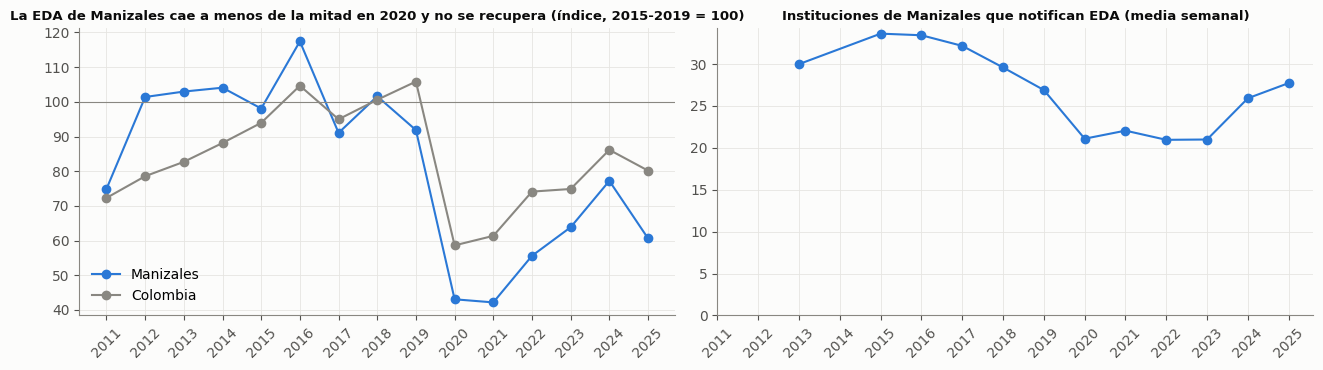

,casos Manizales,índice Manizales,índice Colombia,instituciones por semana
anio,,,,
2011,23337.0,75.0,72.0,NaN
2012,31606.0,101.0,79.0,NaN
2013,32094.0,103.0,83.0,30.0
2014,32442.0,104.0,88.0,NaN
2015,30569.0,98.0,94.0,33.6
2016,36606.0,117.0,105.0,33.4
2017,28382.0,91.0,95.0,32.2
2018,31666.0,102.0,101.0,29.6
2019,28632.0,92.0,106.0,26.9


In [4]:
# la semana que empieza el 2025-12-28 trae 2.495 casos de EDA en Manizales (la mediana semanal es 488): error de la fuente, se excluye
SE53 = pd.Timestamp("2025-12-28")
m998 = m998[~((m998.fecha_inicio_semana == SE53) & (m998.variable == "casos_eda_total"))]
eda = m998[m998.variable == "casos_eda_total"].groupby("anio").valor.sum()
eda_col = vig[(vig.ambito == "colombia") & (vig.evento == 998) & (vig.variable == "casos_eda_total")].groupby("anio").valor.sum()
n998 = m998[m998.variable == "n_instituciones_notificando"].groupby("anio").valor.mean()
base = lambda s: 100 * s / s.loc[2015:2019].mean()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(eda.index, base(eda), "o-", color=AZUL, label="Manizales")
axes[0].plot(eda_col.index, base(eda_col), "o-", color=MUDO, label="Colombia")
axes[0].axhline(100, color=MUDO, lw=.8); axes[0].set_title("La EDA de Manizales cae a menos de la mitad en 2020 y no se recupera (índice, 2015-2019 = 100)", fontsize=9.5); axes[0].legend(loc="lower left")
axes[1].plot(n998.index, n998, "o-", color=AZUL); axes[1].set_title("Instituciones de Manizales que notifican EDA (media semanal)", fontsize=9.5)
axes[1].set_ylim(0, None)
for ax in axes: ax.set_xticks(range(2011, 2026), range(2011, 2026), rotation=45)
plt.tight_layout(); plt.show()
pd.DataFrame({"casos Manizales": eda, "índice Manizales": base(eda).round(0), "índice Colombia": base(eda_col).round(0),
              "instituciones por semana": n998.round(1)})

## Lectura

**La EDA de Manizales cae a menos de la mitad en 2020 y no se ha recuperado del todo.**

| | 2015-2019 | 2020 | 2021 | 2024 | 2025 (sin la SE53) |
|---|---|---|---|---|---|
| Índice Manizales | 91-117 | **43** | **42** | 77 | 61 |
| Índice Colombia | 94-106 | 59 | 61 | 86 | 80 |
| Instituciones por semana | 26,9-33,6 | 21,1 | 22,1 | 25,9 | 27,7 |

- **Manizales cae más que el país** y se recupera menos.
- **Las instituciones que notifican también caen**, de 33,6 por semana en 2015 a unas 21 entre 2020 y 2023. Parte de la caída puede ser de notificación y parte real; **con estos datos no se separan.**
- La cifra de 2025 con la semana errónea incluida sería 21.391 casos (índice 69); sin ella, 18.896.

**Qué se encontró con ella.** La lluvia se asocia con menos EDA de la ciudad (**r = −0,19**, al revés de lo esperado, cuaderno 09). Las semanas largas sin lluvia fuerte suben la familia digestiva un **+15,7 %** (12 de 63 pruebas sobreviven, cuaderno 19). La EDA hospitalizada de Caldas pareció anticipar el triage a 4-6 semanas (+1,6 a +2,0 %), pero era estacionalidad compartida: al quitar la estación del desenlace el efecto cae a −0,3 y −0,5 %, y el triage la «predice» igual de bien dos semanas antes (cuaderno 13).

**Límite.** Las instituciones del 998 no son las del 995: en 2025, 27,7 por semana contra 53,5. La proporción EDA sobre las consultas del 995 es una aproximación.

## 2.3 Eventos individuales: una fila por caso

**Qué es.** Las fichas de notificación individual del SIVIGILA. Se cuentan los casos de Manizales por **municipio de ocurrencia**, por semana epidemiológica.

- **Publica:** INS, los mismos microdatos.
- **Se rehace con** `python calendarios/vigilancia/eventos.py --sin-red` (series desde el crudo; `--descargar --seleccionados` baja 2007-2025 de lo elegido).
- **Rezago:** ~8 meses.
- **Criterio de entrada:** el evento tiene al menos 1 caso por semana, en promedio, en Manizales en 2023-2025. Son 14 series y 3 marcadores. Al leer se aplica una lista blanca: edad, sexo, documento y aseguradora no se leen nunca.

La figura muestra los casos por año de cada uno. **Aviso de fuga:** 300, 875, 356, 365 y 549 son personas que consultan en urgencias, parte del propio desenlace. Solo pueden entrar con rezago o como desenlaces específicos.

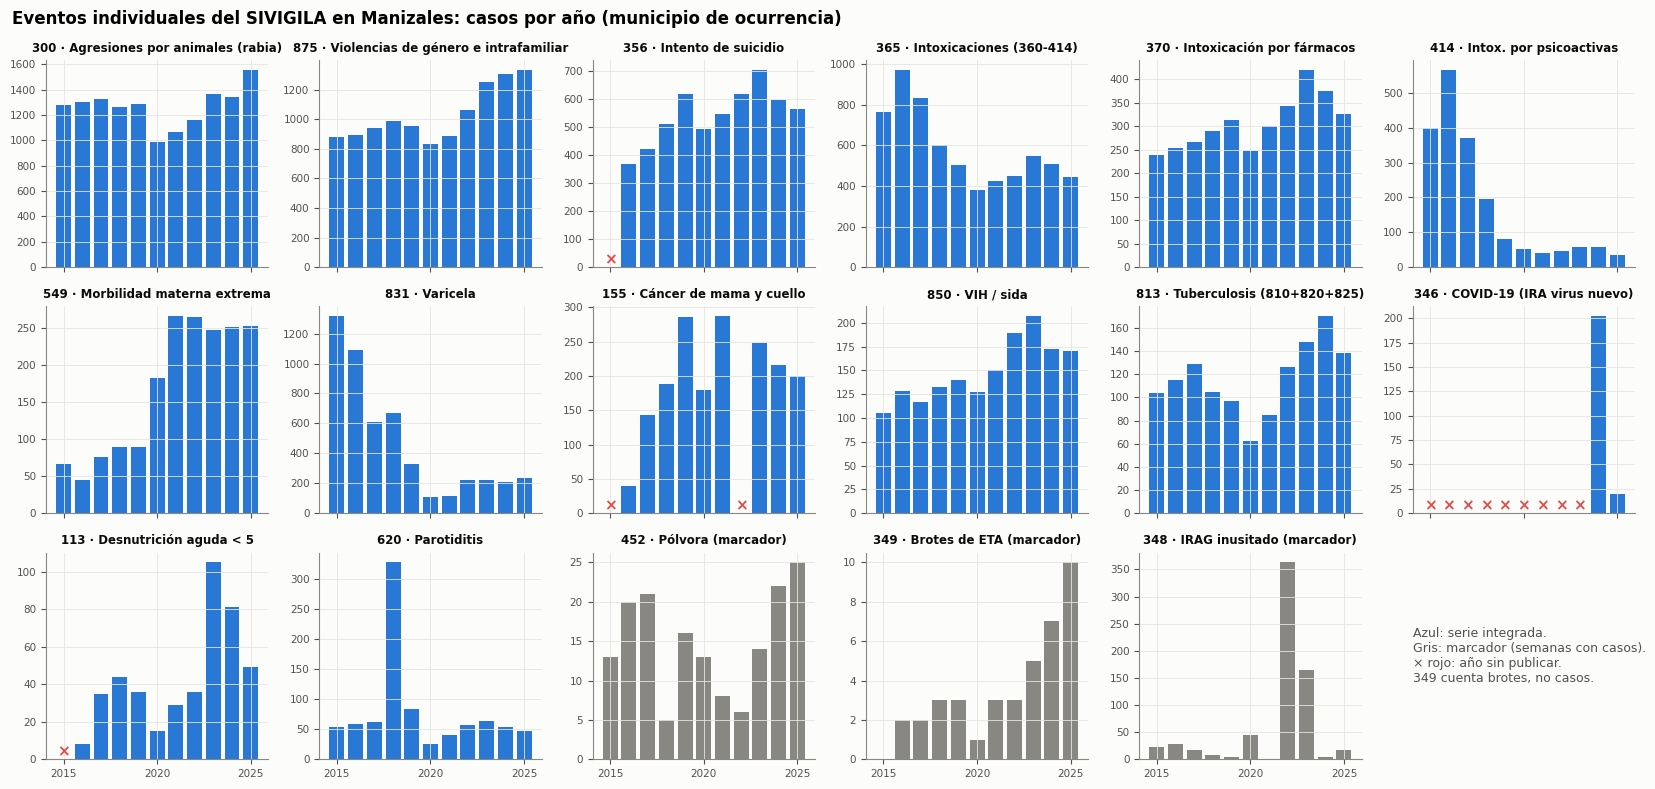

anio,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
300 Agresiones por animales (rabia),1281,1304,1326,1265,1286,984,1069,1163,1364,1345,1555
875 Violencias de género e intrafamiliar,881,893,943,991,953,830,887,1060,1255,1308,1332
356 Intento de suicidio,<NA>,368,422,511,619,493,546,618,703,596,566
365 Intoxicaciones (360-414),767,971,833,603,502,379,423,447,548,510,444
370 Intoxicación por fármacos,239,254,266,289,312,248,300,342,419,375,325
414 Intox. por psicoactivas,399,565,371,194,81,52,41,47,58,58,35
549 Morbilidad materna extrema,66,45,76,90,89,183,266,265,247,251,253
831 Varicela,1316,1089,611,668,328,110,114,224,222,211,237
155 Cáncer de mama y cuello,<NA>,40,143,189,286,180,287,<NA>,248,216,200
850 VIH / sida,105,128,117,133,140,127,151,189,207,173,170


In [5]:
ELEGIDOS = [300, 875, 356, 365, 370, 414, 549, 831, 155, 850, 813, 346, 113, 620, 452, 349, 348]
nombre = {300: "Agresiones por animales (rabia)", 875: "Violencias de género e intrafamiliar", 356: "Intento de suicidio",
          365: "Intoxicaciones (360-414)", 370: "Intoxicación por fármacos", 414: "Intox. por psicoactivas",
          549: "Morbilidad materna extrema", 831: "Varicela", 155: "Cáncer de mama y cuello", 850: "VIH / sida",
          813: "Tuberculosis (810+820+825)", 346: "COVID-19 (IRA virus nuevo)", 113: "Desnutrición aguda < 5",
          620: "Parotiditis", 452: "Pólvora (marcador)", 349: "Brotes de ETA (marcador)", 348: "IRAG inusitado (marcador)"}
em = eve[eve.ambito == "manizales"]
def anual(cod):
    var = "brotes" if cod == 349 else "casos_ocurrencia"
    return em[(em.evento == cod) & (em.variable == var)].groupby("anio").valor.sum().reindex(range(2015, 2026))
AE = pd.DataFrame({c: anual(c) for c in ELEGIDOS})
fig, axes = plt.subplots(3, 6, figsize=(17, 8), sharex=True)
for ax, c in zip(axes.flat, ELEGIDOS):
    marcador = c in (452, 349, 348)
    ax.bar(AE.index, AE[c], color=MUDO if marcador else AZUL, width=.8)
    sin_dato = AE.index[AE[c].isna()]
    for a in sin_dato:
        ax.text(a, 0, "×", ha="center", va="bottom", color=ROJO, fontsize=11, fontweight="bold")
    ax.set_title(f"{c} · {nombre.get(c, '')}", fontsize=8.5); ax.tick_params(labelsize=7.5)
for ax in axes.flat[len(ELEGIDOS):]:
    ax.axis("off")
axes.flat[-1].text(0, .5, transform=axes.flat[-1].transAxes, s="Azul: serie integrada.\nGris: marcador (semanas con casos).\n× rojo: año sin publicar.\n349 cuenta brotes, no casos.",
                   fontsize=9, color=TINTA2, va="center")
for ax in axes[-1]:
    ax.set_xticks([2015, 2020, 2025])
fig.suptitle("Eventos individuales del SIVIGILA en Manizales: casos por año (municipio de ocurrencia)", fontweight="bold", x=.01, ha="left")
plt.tight_layout(); plt.show()
AE.T.rename(index=lambda c: f"{c} {nombre.get(c, '')}").astype("Int64")

## Lectura

**Casi todos los eventos tienen al menos un escalón. Ninguno se puede usar sin mirar su serie.**

| Evento | Escalón | Lo que probablemente es |
|---|---|---|
| 831 Varicela | 1.316 (2015) → 110 (2020): **−92 %** | vacunación y pandemia (inferido) |
| 414 Psicoactivas | 565 (2016) → 41 (2021): **−93 %**. Arrastra al 365: 971 → 423 | cambio de definición o de notificación (inferido) |
| 549 Morbilidad materna extrema | 89 (2019) → 183 (2020) → 266 (2021): **×3** | cambio de notificación (inferido); en el país también sube |
| 113 Desnutrición < 5 años | 36 (2022) → 105 (2023): **×2,9** | sin explicar |
| 155 Cáncer de mama y cuello | empieza en 2016 con 40; **2022 no está publicado** | hueco del portal |
| 348 IRAG inusitado | 363 (2022) y 164 (2023), contra 1-45 los demás años | la ficha absorbió la COVID |
| 346 COVID-19 | solo 2024-2025: 202 y 20 | la ficha nace en 2024 |
| 620 Parotiditis | brote de 2018: 328 | brote real |
| 300 Agresiones por animales | 1.286 (2019) → 984 (2020) | pandemia |
| 875 Violencias | 881 (2015) → 1.332 (2025): **+51 %** | crecimiento sostenido |

**Otro escalón que no se ve en los totales:** el INS cambia, por evento y por año, **qué fecha define la semana** (notificación, inicio de síntomas o consulta). Por ejemplo, el 875 pasa a fecha de consulta en 2020 y el 549 en 2023 (tabla en `calendarios/docs/VIGILANCIA.md`). El total anual no cambia; la semana de cada caso, sí. Para el histórico existe `casos_ocurrencia_semana_consulta`, con la misma definición todos los años, pero no para 2026.

**Qué se encontró con ellos.**
- La Niña sube la enfermedad de la ciudad: violencias **+0,35**, salud mental **+0,31** y varicela **+0,38** desviaciones típicas, por encima del control de falsos descubrimientos (cuaderno 20).
- La pólvora (evento 452) concentra el 80 % de sus casos anuales en diciembre-enero (1,3 por semana), pero en los días pico son uno o dos triages frente a unos 177 de media: forma parte de la noche festiva y no la explica sola (cuaderno 08 y el informe del contexto oficial de los picos, en `calendarios/docs/`).
- Las subidas de la IRA de la ciudad no dejan huella en el SES, ni en día laboral ni en fin de semana (cuaderno 07).

**Qué pueden sostener.** Totales por año y formas de temporada **dentro** de un régimen estable. **Qué no:** comparaciones que crucen un escalón, ni el análisis semana a semana en un evento cuya definición de semana cambió.

## 2.4 Power BI del INS: la vía para 2026

**Qué es.** El tablero público «006 Vigilancia Rutinaria» del INS, publicado con *Publish to web*, más un tablero por evento. Da conteos por evento × semana × municipio.

- **Publica:** INS. La dirección del tablero y su clave se leen en cada corrida de la lista SharePoint `MenuReporteNivel2` de `portalsivigila.ins.gov.co` (detalle en `calendarios/docs/FUENTES_VIGILANCIA.md`).
- **Se rehace con** `python calendarios/vigilancia/powerbi.py`, que **congela** la descarga del día en su carpeta. No se puede rehacer después: el tablero se sobrescribe cada semana. La captura semanal lo hace desde el 2026-09-28.
- **Rezago: ~7 días.** Las 2-3 últimas semanas se revisan por notificación tardía.
- **La interfaz no está documentada.** Solo se piden medidas agregadas: los modelos por evento exponen columnas identificables, que nunca se consultan.

La figura compara la IRA del tablero 995 con la de los microdatos, semana a semana y por año.

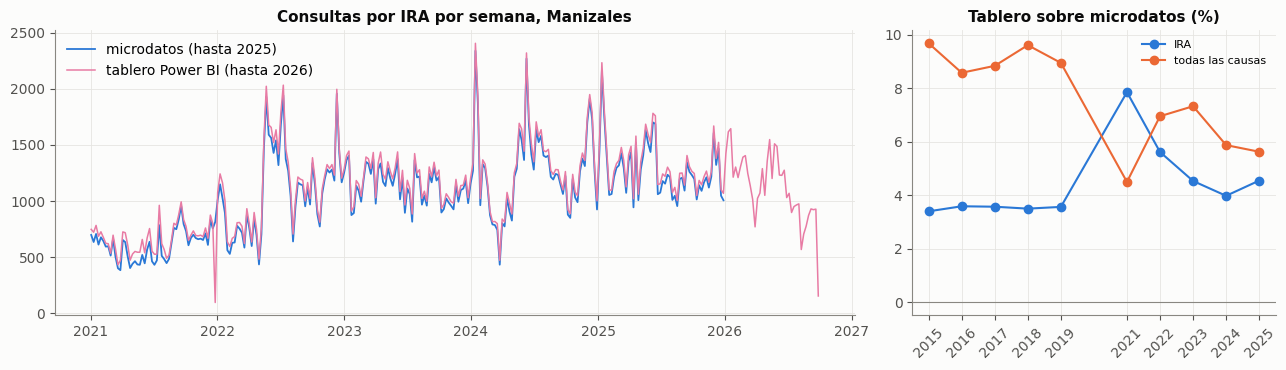

años del tablero 995: [2015, 2016, 2017, 2018, 2019, 2021, 2022, 2023, 2024, 2025, 2026]
semana a semana, 2015-2025: r = 0.994; semanas idénticas: 0 de 521
semanas donde el tablero queda más por debajo de los microdatos: {'2021-12-26': '96 contra 814', '2015-01-04': '1489 contra 1604', '2017-09-17': '1669 contra 1645'}
2026: tablero 995 43,705 IRA en 39 semanas; tabla 995 del 006 41,656 en 39 semanas (-4.7 %)


anio,2015,2016,2017,2018,2019,2021,2022,2023,2024,2025
IRA,3.4,3.6,3.6,3.5,3.6,7.9,5.6,4.5,4.0,4.6
todas las causas,9.7,8.6,8.8,9.6,8.9,4.5,7.0,7.3,5.9,5.6


In [6]:
tb = pbi["ira_995_tablero"].copy()
tb["fecha"] = [inicio_semana_epi(a, s) for a, s in zip(tb.anio, tb.semana)]
tb = tb.set_index("fecha").sort_index()
mi_sem = m995[m995.variable == "consultas_ira_total"].set_index("fecha_inicio_semana").valor.sort_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
axes[0].plot(mi_sem.loc["2021":].index, mi_sem.loc["2021":], color=AZUL, lw=1.3, label="microdatos (hasta 2025)")
axes[0].plot(tb.loc["2021":].index, tb.loc["2021":, "grup_total"], color=MAGENTA, lw=1.1, label="tablero Power BI (hasta 2026)")
axes[0].set_title("Consultas por IRA por semana, Manizales"); axes[0].legend(loc="upper left")
emp = pd.DataFrame({"IRA": tb.groupby("anio").grup_total.sum() / ira - 1,
                    "todas las causas": tb.groupby("anio").Tot_tot.sum() / todas - 1}).dropna() * 100
axes[1].plot(emp.index, emp["IRA"], "o-", color=AZUL, label="IRA")
axes[1].plot(emp.index, emp["todas las causas"], "o-", color=NARANJA, label="todas las causas")
axes[1].axhline(0, color=MUDO, lw=.8); axes[1].set_title("Tablero sobre microdatos (%)"); axes[1].legend(fontsize=8)
axes[1].set_xticks(emp.index, emp.index, rotation=45)
plt.tight_layout(); plt.show()
r_sem = pd.concat([mi_sem, tb.grup_total], axis=1, keys=["m", "t"]).dropna()
print(f"años del tablero 995: {sorted(tb.anio.unique())}")
print(f"semana a semana, 2015-2025: r = {r_sem.m.corr(r_sem.t):.3f}; semanas idénticas: {(r_sem.m == r_sem.t).sum()} de {len(r_sem)}")
peores = (r_sem.t / r_sem.m - 1).mul(100).sort_values().head(3)
print("semanas donde el tablero queda más por debajo de los microdatos:",
      {f"{d:%Y-%m-%d}": f"{int(r_sem.t[d])} contra {int(r_sem.m[d])}" for d in peores.index})
r26 = pbi["ira_995_rutinaria"]
print(f"2026: tablero 995 {int(tb.loc[tb.anio == 2026, 'grup_total'].sum()):,} IRA en {int((tb.anio == 2026).sum())} semanas; "
      f"tabla 995 del 006 {int(r26.consultas_ira.sum()):,} en {len(r26)} semanas "
      f"({100 * (r26.consultas_ira.sum() / tb.loc[tb.anio == 2026, 'grup_total'].sum() - 1):+.1f} %)")
emp.round(1).T

In [7]:
filas = []
for k in ["300", "356", "831", "875"]:
    t = pbi[f"evento_{k}"].groupby("anio").casos.sum()
    m = anual(int(k))
    for a in range(2022, 2026):
        filas.append({"evento": int(k), "año": a, "tablero": int(t.get(a, 0)), "microdatos": int(m.get(a, 0)),
                      "diferencia %": round(100 * (t.get(a, 0) / m.get(a, np.nan) - 1), 1)})
E = pd.DataFrame(filas)
display(E.pivot(index="evento", columns="año", values="diferencia %"))
top = rut.groupby(["cod_eve", "nom_eve"]).casos.sum().sort_values(ascending=False)
print(f"006 de 2026, Manizales: {rut.cod_eve.nunique()} eventos, {int(rut.casos.sum()):,} casos, SE1 a SE{rut.semana.max()}")
top.head(10).rename(lambda s: s[:45] if isinstance(s, str) else s).to_frame("casos 2026")

año,2022,2023,2024,2025
evento,,,,
300,-1.2,-0.1,-8.3,-1.1
356,-1.0,1.1,0.8,1.6
831,1.3,-0.9,1.4,-0.4
875,0.3,1.5,0.4,-0.3


006 de 2026, Manizales: 29 eventos, 3,877 casos, SE1 a SE39


,,casos 2026
cod_eve,nom_eve,
300,AGRESIONES POR ANIMALES POTENCIALMENTE TRANSM,1141
875,VIGILANCIA EN SALUD PÚBLICA DE LA VIOLENCIA D,931
356,INTENTO DE SUICIDIO,489
365,INTOXICACIONES,354
549,MORBILIDAD MATERNA EXTREMA,221
155,CÁNCER DE LA MAMA Y CUELLO UTERINO,155
831,VARICELA INDIVIDUAL,155
850,VIH/SIDA/MORTALIDAD POR SIDA,105
813,TUBERCULOSIS,83


## Lectura

**El tablero cuadra en la forma y no en el nivel.**

- **IRA del tablero 995: de +3,4 a +7,9 % por encima de los microdatos todos los años.** Todas las causas, de +4,5 a +9,7 %. Semana a semana, r = 0,994 y **ninguna de 521 semanas es idéntica**: es un nivel, no un desfase. Para empalmar 2026 se necesita un factor de nivel por año, o usar la proporción, que ya es un cociente.
- **Hay una semana rota en el tablero:** la que empieza el 2021-12-26 (SE52 de 2021) da 96 consultas contra 814 en los microdatos. Es la caída que se ve a comienzos de 2022 en la figura.
- **Dentro de 2026, dos tablas del mismo INS no coinciden:** en la instantánea del 2026-10-05, el tablero 995 da 43.705 IRA en 39 semanas y la tabla 995 del 006, 41.656 (−4,7 %).
- **Eventos por tablero contra microdatos:** dentro del ±1,6 % por año en 356, 831 y 875; el **300 de 2024 queda −8,3 %**, sin explicar.
- **El 006 de 2026** trae 29 eventos y 3.877 casos de Manizales, de la SE1 a la SE39. Todas las cifras de Power BI de este cuaderno corresponden a la captura fija del 2026-10-05; capturas posteriores darán valores distintos.

**Qué se encontró con ella.** La IRA de Manizales que se puede calcular a tiempo con Power BI tiene una anomalía que correlaciona **0,989** con la de los microdatos. Pero la anomalía operativa, que no usa la media del año entero (que en operación no se conoce), correlaciona **0,806** con la del cuaderno de análisis, de modo que los resultados se vuelven a medir con la anomalía operativa (cuaderno 13).

**Límites.**
- Hay **dos instantáneas** (2026-09-28 y 2026-10-05). Evaluar un pronóstico «con lo que se sabía en su momento» solo será posible hacia adelante, a medida que la captura semanal acumule historia.
- **Qué semana usa el 006 no está verificado**: los tableros por evento no usan todos la misma definición.

---
# 3. Clima

**Qué es.** Una fila por día con temperatura, lluvia, humedad, viento y radiación. Une cuatro fuentes: cada variable tiene una referencia medida en Manizales, y las demás se llevan a su escala mes a mes antes de tomar la mediana.

| Fuente | Quién la publica | Dónde |
|---|---|---|
| Estaciones IDEAM (Tesorito, 7,7 km; La Nubia, 5,0 km) | IDEAM | datos.gov.co, `s54a-sgyg` (precipitación) y `sbwg-7ju4` (temperatura) |
| METAR del aeropuerto La Nubia (SKMZ) | Aerocivil, vía Iowa Environmental Mesonet | `https://mesonet.agron.iastate.edu/api/1/daily.txt` |
| Reanálisis ERA5-Land / ERA5 | Copernicus, vía Open-Meteo | `https://archive-api.open-meteo.com/v1/archive` |
| Reanálisis MERRA-2 / satélite | NASA POWER | `https://power.larc.nasa.gov/api/temporal/daily/point` |

- **Se rehace con** `python calendarios/clima/clima_manizales.py` (descarga) y `python calendarios/clima/clima_unificado.py` (une y audita).
- **Rezago:** días. **Cobertura:** 2020-01-01 a 2026-08-28.
- **La columna «IDEAM» no es una estación sino tres empalmadas.** Planalto (12,8 km, de Cenicafé, unos 800 m más abajo) cubre de agosto de 2020 a septiembre de 2023 con 21,0 °C de media y un sesgo de +7,39 °C en la máxima: no es Manizales y se excluye. La referencia de temperatura es La Nubia, donde el METAR y la estación IDEAM, que son la misma pista con dos redes distintas, coinciden con r = 0,81 y 0,29 °C de sesgo.
- **Referencia de la lluvia: el pluviómetro IDEAM.** NASA POWER da casi el doble de lluvia anual (1.904 mm contra 1.083 y 1.172) y llueve tres de cada cuatro días (73 %, contra 34-39 % de los pluviómetros), la llovizna típica de los productos satelitales; con NASA de referencia casi no habría días secos y no habría transición de seco a lluvioso que detectar. Donde no hay pluviómetro se usa NASA escalado al mes, que acierta el total del mes pero no el día (r = 0,18 con la estación, día a día).
- **Un defecto de una versión anterior del consenso lo ilustra.** Con la mediana de fuentes sin escalar, los días sin pluviómetro tenían +20,05 mm/día más que los días con él dentro del mismo mes (tras reescribirlo, −0,36): cada vez que la estación dejaba de reportar aparecía una tormenta, que es justo el cambio brusco que se busca. Todo lo calculado con esa versión se descartó.
- **Es clima observado.** Para pronosticar de verdad se necesita el pronóstico archivado (Open-Meteo), que existe pero no está integrado (sección 8).

La primera figura mira la **medida en tierra** que hay debajo del consenso. En el panel 2, para cada mes, la lluvia que sumó el pluviómetro en sus días con lectura contra la que dio NASA **esos mismos días**: no tienen por qué coincidir en nivel, pero sí deben subir y bajar juntas. El archivo actual no conserva la lectura del pluviómetro en los días de falla; para poder verla, la celda rehace la unión con el mismo programa **sin la detección de la falla** y comprueba que con la detección puesta reproduce exactamente el archivo. Las figuras y tablas de esta celda usan esa lectura cruda; en rojo, los días que ahora se descartan. La tabla anual trae al final las dos columnas del clima con la falla tratada.

comprobación: la unión rehecha con la detección da el archivo actual; diferencia máxima del consenso = 3.6e-15 mm


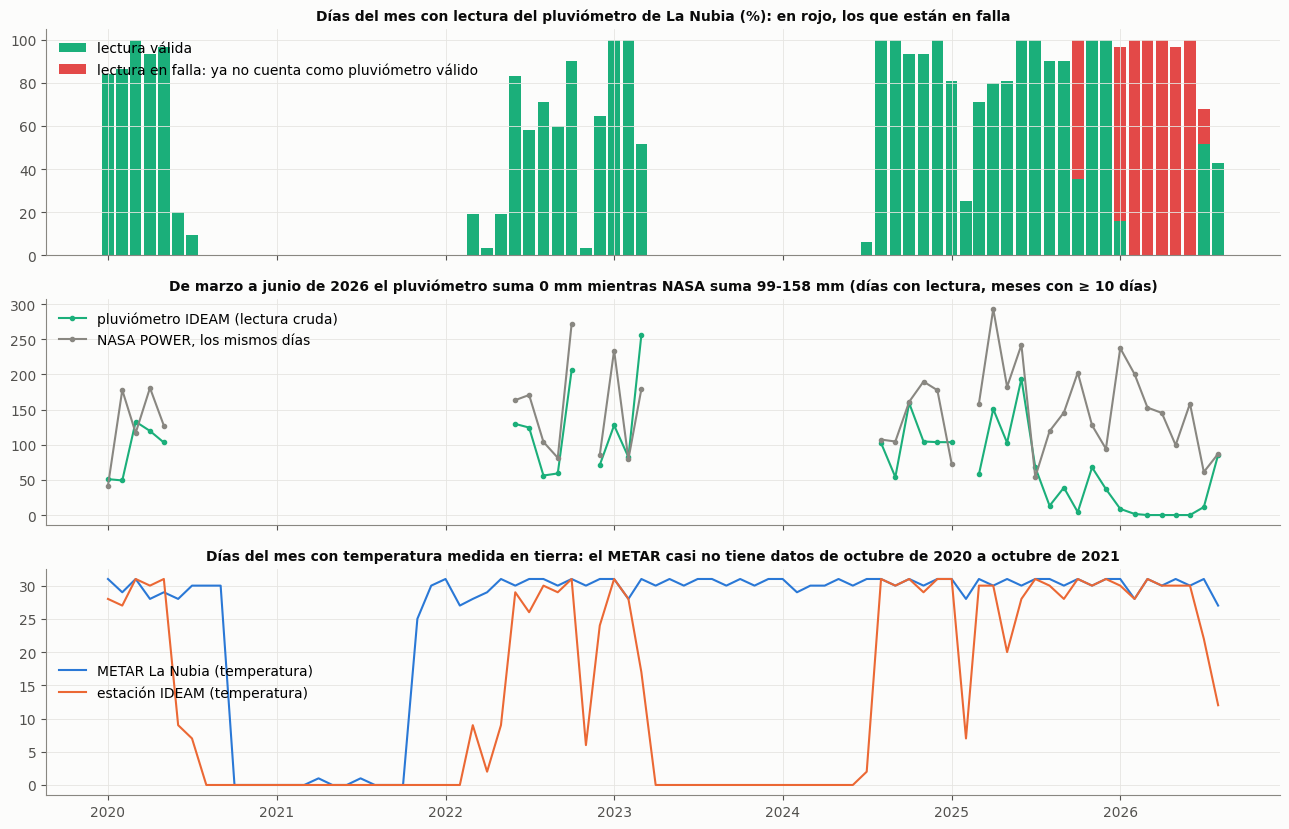

último día con ≥ 1 mm en el pluviómetro (crudo) antes de julio de 2026: 2026-01-02


fecha,2025-07-01,2025-08-01,2025-09-01,2025-10-01,2025-11-01,2025-12-01,2026-01-01,2026-02-01,2026-03-01,2026-04-01,2026-05-01,2026-06-01,2026-07-01,2026-08-01
días de estación,31,28,27,31,30,31,30,28,31,30,30,30,21,12
pluviómetro mm,68,13,39,4,67,37,8,1,0,0,0,0,11,85
"NASA mm, mismos días",54,119,145,202,127,94,237,200,152,145,99,158,61,87
días marcados como falla,0,0,0,20,0,0,25,28,31,30,30,30,5,0


,% días con pluviómetro,"pluviómetro / NASA, mismos días",r diaria pluviómetro-NASA,% días con ≥ 1 mm en el pluviómetro,lluvia consenso mm,"% días con pluviómetro, corregido","lluvia consenso mm, corregida",días METAR,días en el archivo
fecha,,,,,,,,,
2020,40.71,0.71,0.29,38.93,937.43,40.71,1073.67,266,366
2021,0.00,NaN,NaN,NaN,664.23,0.00,828.36,57,365
2022,39.73,0.75,0.49,64.14,1460.13,39.73,1728.52,360,365
2023,20.55,0.95,0.23,54.67,1178.10,20.55,1390.07,365,365
2024,41.26,0.72,0.29,35.10,1180.62,41.26,1423.87,365,366
2025,85.21,0.49,0.12,35.37,1063.02,79.73,1309.55,365,365
2026,88.33,0.09,0.25,3.77,403.63,13.75,875.11,239,240


In [8]:
# El archivo actual no guarda la lectura del pluviómetro en los días de falla (la pone en NaN). Para verla se
# rehace la unión con el mismo script y la detección desactivada: reproduce el clima sin tratar la falla.
sys.path.insert(0, str(CAL / "clima"))
import clima_unificado as cu
_detector = cu.pluviometro_fallido
cu.pluviometro_fallido = lambda c: pd.Series(False, index=c.index)
try:
    antes = cu.unir().set_index("fecha").reindex(clima.index)      # el clima sin tratar la falla
finally:
    cu.pluviometro_fallido = _detector
crudo = antes.precipitacion_mm                                       # el pluviometro tal como lo reporta IDEAM
print("comprobación: la unión rehecha con la detección da el archivo actual; diferencia máxima del consenso =",
      f"{(cu.unir().set_index('fecha').reindex(clima.index).precip_consenso_mm - clima.precip_consenso_mm).abs().max():.1e} mm")

est = crudo.notna()                                                  # dia con lectura del pluviometro (crudo)
mes = clima.index.to_period("M")
M = pd.DataFrame({
    "% días con pluviómetro": 100 * est.groupby(mes).mean(),
    "pluviómetro mm": crudo.where(est).groupby(mes).sum(),
    "NASA mm, mismos días": clima.np_PRECTOTCORR.where(est).groupby(mes).sum(),
    "días marcados como falla": FALLA.groupby(mes).sum(),
    "días de estación": est.groupby(mes).sum(),
    "días METAR": clima.iem_tmedia_c.notna().groupby(mes).sum(),
    "días IDEAM temp.": clima.temp_media.notna().groupby(mes).sum()})
M.index = M.index.to_timestamp()
fig, axes = plt.subplots(3, 1, figsize=(13, 8.4), sharex=True)
pct_falla = 100 * M["días marcados como falla"] / M.index.days_in_month
axes[0].bar(M.index, M["% días con pluviómetro"] - pct_falla, width=25, color=AQUA, label="lectura válida")
axes[0].bar(M.index, pct_falla, bottom=M["% días con pluviómetro"] - pct_falla, width=25, color=ROJO,
            label="lectura en falla: ya no cuenta como pluviómetro válido")
axes[0].set_title("Días del mes con lectura del pluviómetro de La Nubia (%): en rojo, los que están en falla", fontsize=10); axes[0].set_ylim(0, 105); axes[0].legend(loc="upper left")
ok = M["días de estación"] >= 10
axes[1].plot(M.index, M["pluviómetro mm"].where(ok), "o-", ms=3, color=AQUA, label="pluviómetro IDEAM (lectura cruda)")
axes[1].plot(M.index, M["NASA mm, mismos días"].where(ok), "o-", ms=3, color=MUDO, label="NASA POWER, los mismos días")
axes[1].set_title("De marzo a junio de 2026 el pluviómetro suma 0 mm mientras NASA suma 99-158 mm (días con lectura, meses con ≥ 10 días)", fontsize=10); axes[1].legend(loc="upper left")
axes[2].plot(M.index, M["días METAR"], color=AZUL, label="METAR La Nubia (temperatura)")
axes[2].plot(M.index, M["días IDEAM temp."], color=NARANJA, label="estación IDEAM (temperatura)")
axes[2].set_title("Días del mes con temperatura medida en tierra: el METAR casi no tiene datos de octubre de 2020 a octubre de 2021", fontsize=10); axes[2].legend(loc="center left", ncol=1)
axes[2].xaxis.set_major_locator(mdates.YearLocator()); axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout(); plt.show()

anio = clima.index.year
dc = pd.DataFrame({"p": crudo, "n": clima.np_PRECTOTCORR})
Y = pd.DataFrame({"% días con pluviómetro": 100 * est.groupby(anio).mean(),
                  "pluviómetro / NASA, mismos días": crudo.where(est).groupby(anio).sum() / clima.np_PRECTOTCORR.where(est).groupby(anio).sum(),
                  "r diaria pluviómetro-NASA": [dc[anio == a].dropna().corr().iloc[0, 1] if est[anio == a].sum() > 20 else np.nan for a in sorted(set(anio))],
                  "% días con ≥ 1 mm en el pluviómetro": 100 * (crudo >= 1).groupby(anio).sum() / est.groupby(anio).sum(),
                  "lluvia consenso mm": antes.precip_consenso_mm.groupby(anio).sum(),
                  "% días con pluviómetro, corregido": 100 * clima.precip_con_estacion.groupby(anio).mean(),
                  "lluvia consenso mm, corregida": clima.precip_consenso_mm.groupby(anio).sum(),
                  "días METAR": clima.iem_tmedia_c.notna().groupby(anio).sum(),
                  "días en el archivo": anio.value_counts().sort_index()}).round(2)
ultimo = crudo.loc[:"2026-06-30"]
print("último día con ≥ 1 mm en el pluviómetro (crudo) antes de julio de 2026:", f"{ultimo[ultimo >= 1].index.max():%Y-%m-%d}")
sin_lluvia = M.loc["2025-07":"2026-08", ["días de estación", "pluviómetro mm", "NASA mm, mismos días", "días marcados como falla"]]
display(sin_lluvia.astype(int).T)
Y

## Lectura

**Desde octubre de 2025 el pluviómetro de La Nubia reporta casi cero, y sin tratamiento el consenso lo toma como dato bueno.**

| Mes | 2025-10 | 2026-01 | 2026-02 | 2026-03 | 2026-04 | 2026-05 | 2026-06 | 2026-08 |
|---|---|---|---|---|---|---|---|---|
| Días con pluviómetro | 31 | 30 | 28 | 31 | 30 | 30 | 30 | 12 |
| Pluviómetro, mm | 4 | 8 | 1 | **0** | **0** | **0** | **0** | 85 |
| NASA, mismos días, mm | 202 | 237 | 200 | 152 | 145 | 99 | 158 | 87 |

- **El último día con 1 mm o más antes de julio de 2026 es el 2026-01-02.** Cuatro meses enteros de la primera temporada de lluvias, de marzo a junio de 2026, en cero exacto.
- Por año, el cociente pluviómetro / NASA en los mismos días era de 0,71 a 0,95 en 2020-2024. Cae a **0,49 en 2025 y 0,09 en 2026**, y la correlación diaria baja a 0,12 en 2025.
- **La «cobertura» del 85 y el 88 % de 2025 y 2026 es engañosa:** esos días tienen registro, pero el registro es falso, y un filtro de completitud no lo detecta.
- En agosto de 2026 vuelve a coincidir con NASA (85 contra 87 mm): la estación parece reparada.

**Otros dos huecos de la medida en tierra.** En 2021 no hay ni un día de pluviómetro y solo 57 de METAR: todo 2021 es reanálisis. Tampoco hay pluviómetro de abril de 2023 a junio de 2024.

**Consecuencia.** Sin tratar la falla, cualquier variable de lluvia de octubre de 2025 a junio de 2026, diaria o acumulada, estaría contaminada, incluidas las transiciones «seco → lluvioso». La sección 3.1 detecta la falla y la 3.2 mide qué cambia al tratarla.

## 3.1 La falla detectada: la columna `pluviometro_fallido`

El criterio se fijó antes de regenerar el archivo: un día se marca como falla cuando, **en los 31 días centrados en él**, el pluviómetro suma menos del **10 %** de lo que suma NASA en los mismos días, y NASA suma al menos **60 mm**. La ventana es de un mes y no de un día a propósito: un día seco aislado es real; un mes entero en cero mientras el satélite ve lluvia, no. La falla se quita **antes** de calcular los factores con que se escala NASA a la escala del pluviómetro.

La figura dibuja las dos condiciones sobre la lectura cruda, de julio de 2024 a agosto de 2026. En sombreado, los días que el programa marca.

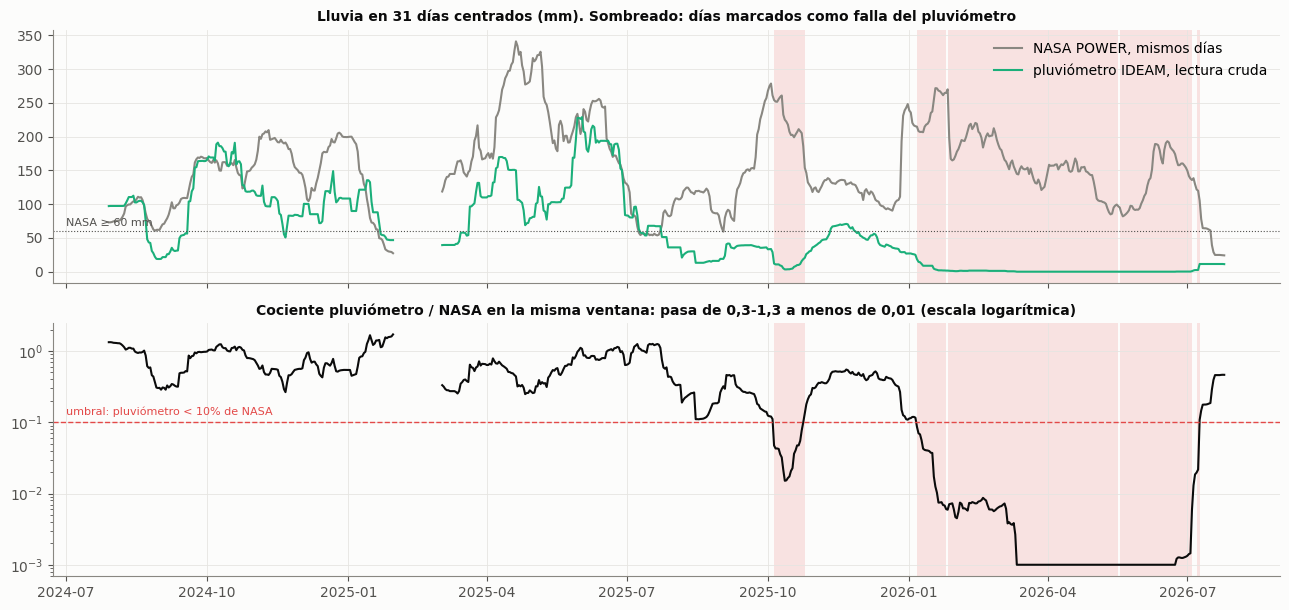

meses sanos (29): razón pluviómetro/NASA de 0.11 a 1.43, mediana 0.73
meses con ≥ 15 días en falla (7): razón de 0.000 a 0.037
razón pluviómetro/NASA de 2025-08: 0.111
días marcados: 199  (primero 2025-10-05, último 2026-07-08)


fecha,2025-10,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07
días en falla,20,25,28,31,30,30,30,5


In [9]:
# El criterio de clima_unificado.pluviometro_fallido, dibujado: sumas de 31 dias centrados en los dias
# con lectura del pluviometro y de NASA a la vez.
ambos = crudo.notna() & clima.np_PRECTOTCORR.notna()
vent = dict(window=cu.FALLA_VENTANA_DIAS, center=True, min_periods=15)
s_p = crudo.where(ambos).rolling(**vent).sum()
s_n = clima.np_PRECTOTCORR.where(ambos).rolling(**vent).sum()
V0, V1 = "2024-07-01", "2026-08-31"
fig, axes = plt.subplots(2, 1, figsize=(13, 6.2), sharex=True)
for ax in axes:
    for ini, dur in tramos(FALLA.loc[V0:V1]):
        ax.axvspan(ini, ini + dur, color=ROJO, alpha=.14, lw=0)
axes[0].plot(s_n.loc[V0:V1].index, s_n.loc[V0:V1], color=MUDO, label="NASA POWER, mismos días")
axes[0].plot(s_p.loc[V0:V1].index, s_p.loc[V0:V1], color=AQUA, label="pluviómetro IDEAM, lectura cruda")
axes[0].axhline(cu.FALLA_NASA_MINIMA_MM, color=TINTA2, lw=.8, ls=":")
axes[0].text(pd.Timestamp(V0), cu.FALLA_NASA_MINIMA_MM + 8, f"NASA ≥ {cu.FALLA_NASA_MINIMA_MM:.0f} mm", fontsize=8, color=TINTA2)
axes[0].set_title("Lluvia en 31 días centrados (mm). Sombreado: días marcados como falla del pluviómetro", fontsize=10); axes[0].legend(loc="upper right")
razon = (s_p / s_n).where(s_n > 0)
axes[1].plot(razon.loc[V0:V1].index, razon.loc[V0:V1].clip(lower=1e-3), color=TINTA)
axes[1].axhline(cu.FALLA_RAZON_MAXIMA, color=ROJO, lw=1, ls="--")
axes[1].text(pd.Timestamp(V0), cu.FALLA_RAZON_MAXIMA * 1.25, f"umbral: pluviómetro < {cu.FALLA_RAZON_MAXIMA:.0%} de NASA", fontsize=8, color=ROJO)
axes[1].set_yscale("log"); axes[1].set_title("Cociente pluviómetro / NASA en la misma ventana: pasa de 0,3-1,3 a menos de 0,01 (escala logarítmica)", fontsize=10)
axes[1].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10])); axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.tight_layout(); plt.show()

# razon mensual en los meses con >= 15 dias con lectura, sanos contra fallidos
mm = clima.index.to_period("M")
RM = pd.DataFrame({"dias": ambos.groupby(mm).sum(), "falla": FALLA.groupby(mm).sum(),
                   "razon": crudo.where(ambos).groupby(mm).sum() / clima.np_PRECTOTCORR.where(ambos).groupby(mm).sum()})
RM = RM[RM.dias >= 15]
sanos, fallidos = RM[RM.falla == 0].razon, RM[RM.falla >= 15].razon
print(f"meses sanos ({len(sanos)}): razón pluviómetro/NASA de {sanos.min():.2f} a {sanos.max():.2f}, mediana {sanos.median():.2f}")
print(f"meses con ≥ 15 días en falla ({len(fallidos)}): razón de {fallidos.min():.3f} a {fallidos.max():.3f}")
print("razón pluviómetro/NASA de 2025-08:", round(float(RM.loc["2025-08", "razon"]), 3))
print(f"días marcados: {FALLA.sum()}  (primero {FALLA[FALLA].index.min():%Y-%m-%d}, último {FALLA[FALLA].index.max():%Y-%m-%d})")
FALLA.groupby(mm).sum()[lambda s: s > 0].rename("días en falla").to_frame().T

## Lectura

**La falla se separa de la lluvia normal por un orden de magnitud.**

| | Meses | Razón pluviómetro / NASA |
|---|---|---|
| Sin ningún día marcado (con 15 días o más de lectura) | 29 | 0,11 a 1,43; mediana 0,73 |
| Con 15 días o más marcados | 7 | **0,000 a 0,037** |

- **199 días marcados, del 2025-10-05 al 2026-07-08**: 20 en octubre de 2025, 25 en enero de 2026, todos los de febrero a junio y 5 en julio. Noviembre y diciembre de 2025 quedan fuera: el pluviómetro volvió a medir (0,53 y 0,39 de NASA).
- En el panel de abajo, la razón pasa de la franja 0,3-1,3 a menos de 0,01 y se queda ahí de febrero a junio de 2026. En julio sube de golpe: la estación vuelve.
- Tratarlos como días sin pluviómetro deja el **34,7 %** de los días con pluviómetro válido y una lluvia anual del consenso de 1.297 mm.

**Límite.** Agosto de 2025 no se marca y está a una centésima del umbral: 13 mm de pluviómetro contra 119 de NASA, razón 0,111 (se imprime arriba). Puede ser un mes seco de verdad en la estación o el comienzo de la falla; el criterio no lo distingue y queda como dato de pluviómetro.

## 3.2 La serie de lluvia, con y sin tratar la falla

La lluvia del consenso, mes a mes, por año. Si la estación averiada arrastra al consenso, 2026 debe salir como un año seco sin serlo; la línea roja discontinua es 2026 sin tratar la falla. Al final se cuentan los episodios «seco → lluvioso» (la definición del cuaderno 07) con los dos climas, para ver cuáles se mantienen, cuáles desaparecen y cuáles aparecen.

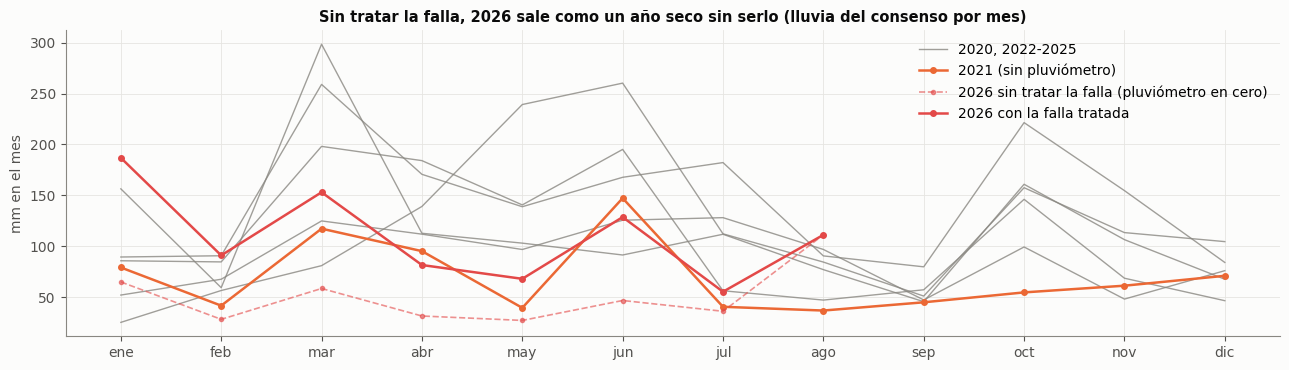

episodios seco -> lluvioso (definición del 07), clima sin tratar la falla: 13; con días en falla en sus 28 días: ['2026-01-12']
episodios con la falla tratada: 17
  se mantienen: ['2022-09-15', '2023-02-19', '2023-07-06', '2023-08-22', '2023-10-07', '2023-12-17', '2024-02-04', '2024-04-03', '2024-08-07', '2024-09-26', '2025-09-19']
  desaparecen:  ['2023-01-01', '2026-01-12']
  aparecen:     ['2022-07-26', '2023-01-05', '2025-01-05', '2026-01-11', '2026-06-24', '2026-08-21']

lluvia del consenso por mes, octubre de 2025 a agosto de 2026 (mm):


fecha,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
sin tratar,61,69,46,65,28,58,31,27,47,36,111
tratada,146,69,46,187,91,153,81,68,129,55,111


anio,2020,2021,2022,2023,2024,2025,2026
mes,,,,,,,
1,52,79,89,156,25,86,187
2,68,42,91,59,56,85,91
3,125,117,259,298,81,198,153
4,112,95,171,113,139,184,81
5,97,39,139,103,239,141,68
6,126,147,168,91,260,195,129
7,128,40,182,112,112,56,55
8,97,37,90,77,84,47,111
9,47,45,80,45,51,57,<NA>


In [10]:
C = clima.precip_consenso_mm.resample("MS").sum(min_count=20).to_frame("mm")
C["anio"], C["mes"] = C.index.year, C.index.month
P = C.pivot(index="mes", columns="anio", values="mm")
A = antes.precip_consenso_mm.resample("MS").sum(min_count=20).to_frame("mm")
A["anio"], A["mes"] = A.index.year, A.index.month
PA = A.pivot(index="mes", columns="anio", values="mm")
fig, ax = plt.subplots(figsize=(13, 3.8))
for a in P.columns:
    if a in (2021, 2026):
        continue
    ax.plot(P.index, P[a], color=MUDO, lw=1, alpha=.8, label="2020, 2022-2025" if a == 2020 else None)
ax.plot(P.index, P[2021], "o-", color=NARANJA, lw=1.8, ms=4, label="2021 (sin pluviómetro)")
ax.plot(PA.index, PA[2026], "o--", color=ROJO, lw=1.2, ms=3, alpha=.6, label="2026 sin tratar la falla (pluviómetro en cero)")
ax.plot(P.index, P[2026], "o-", color=ROJO, lw=1.8, ms=4, label="2026 con la falla tratada")
ax.set_xticks(range(1, 13), ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"])
ax.set_ylabel("mm en el mes"); ax.set_title("Sin tratar la falla, 2026 sale como un año seco sin serlo (lluvia del consenso por mes)", fontsize=10.5); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

# los episodios "seco -> lluvioso" del cuaderno 07 (misma definición), con el clima sin tratar la falla y con la falla tratada
def episodios(serie):
    pr = serie.reindex(pd.date_range("2020-01-01", "2026-09-20"))
    p7, p21 = pr.rolling(7).sum(), pr.shift(7).rolling(21).sum() / 3
    z = lambda x: (x - x.groupby(x.index.month).transform("mean")) / x.groupby(x.index.month).transform("std")
    senal = (z(p7) >= 1) & (z(p21) <= -.5)
    ep, ult = [], None
    for d in senal[senal].index:
        if ult is None or (d - ult).days >= 28:
            ep.append(d); ult = d
    return [d for d in ep if pd.Timestamp("2022-03-01") <= d <= pd.Timestamp("2026-08-23")]
ep_a, ep_d = episodios(antes.precip_consenso_mm), episodios(clima.precip_consenso_mm)
f = lambda L: [f"{d:%Y-%m-%d}" for d in L]
malos = [d for d in ep_a if FALLA.loc[d - pd.Timedelta(days=27):d].any()]
print(f"episodios seco -> lluvioso (definición del 07), clima sin tratar la falla: {len(ep_a)}; con días en falla en sus 28 días: {f(malos)}")
print(f"episodios con la falla tratada: {len(ep_d)}")
print("  se mantienen:", f(sorted(set(ep_a) & set(ep_d))))
print("  desaparecen: ", f(sorted(set(ep_a) - set(ep_d))))
print("  aparecen:    ", f(sorted(set(ep_d) - set(ep_a))))
print("\nlluvia del consenso por mes, octubre de 2025 a agosto de 2026 (mm):")
display(pd.DataFrame({"sin tratar": antes.precip_consenso_mm.resample("MS").sum(), "tratada": clima.precip_consenso_mm.resample("MS").sum()})
        .loc["2025-10":"2026-08"].round(0).astype(int).T.rename(columns=lambda d: f"{d:%Y-%m}"))
P.round(0).astype("Int64")

## Lectura

- **Sin tratar la falla, marzo a junio de 2026 daban 58, 31, 27 y 47 mm**, los meses más secos de toda la serie en los cuatro casos, con la primera temporada de lluvias en curso. **Tratada la falla dan 153, 81, 68 y 129 mm.** Marzo y junio quedan dentro del rango de los demás años y mayo por encima de 2021 (39). Abril sigue siendo el más seco de su mes (81 contra 95-184), pero ya sobre NASA escalado y no sobre un cero. También cambian octubre de 2025 (61 → 146), enero (65 → 187), febrero (28 → 91) y julio de 2026 (36 → 55); noviembre, diciembre y agosto, sin días marcados, no se mueven.
- **Sube todo el nivel, también en los años sin falla**: 2020, 937 → 1.074 mm; 2021, 664 → 828; 2022, 1.460 → 1.729; 2023, 1.178 → 1.390; 2024, 1.181 → 1.424 (de +15 a +25 %). No es que lloviera más: los ceros de la falla entraban en el factor con que se escala NASA, que se calcula **por mes del calendario**, y lo encogían en todos los años. Por eso la subida se concentra en enero a julio y en octubre, los meses con días marcados. **No se pueden comparar los niveles de lluvia del clima sin tratar con los del clima tratado.**
- **2021 sigue siendo el año más seco** (664 → 828 mm, contra 1.074-1.729 los demás años completos) y no tiene ninguna medida en tierra; su nivel es reanálisis puro y no se sabe si es real.
- **Episodios «seco → lluvioso»: 13 → 17.** Se mantienen 11. Dos solo se corren unos días (2023-01-01 → 2023-01-05 y 2026-01-12 → 2026-01-11, este último ahora sobre NASA escalado). Aparecen cuatro nuevos: 2022-07-26, 2025-01-05, 2026-06-24 y 2026-08-21; los de 2022 y 2025 caen fuera de la falla y aparecen porque el nuevo nivel cambia las medias y desviaciones de cada mes con que se calcula el puntaje z.

**Qué se encontró con los episodios.** Con los 17 episodios, el cuaderno 07 da para los 0-4 años **+13,4 ± 15,0 % a los 7-13 días y +10,0 ± 16,4 % a los 14-20**: conserva la forma, pero ya no se distingue de cero. La madrugada con lluvia fuerte pasa de −7,8 a −4,3 %, tampoco significativo. El tratamiento de la falla anuló los resultados calculados sobre el clima sin tratar.

**Qué puede sostener el clima unificado.** La temperatura, en todo el periodo, con 2021 apoyado solo en reanálisis. La lluvia de 2022-2025 en acumulados de 7 días o más; la de octubre de 2025 a julio de 2026 existe, pero es NASA escalado y vale para acumulados de 7 días o más, no para el día exacto. **Qué no:** transiciones día a día de lluvia en 2021, ni rachas secas sacadas del consenso (en los días con pluviómetro válido el pluviómetro marca lluvia el 43,0 % de los días y el consenso el 66,0 %, porque la mediana promedia el pluviómetro con la llovizna de NASA).

## 3.3 Clima completo: reanálisis desde 2010

**Qué es.** `calendarios/clima_completo.csv.gz`: reanálisis de La Nubia desde 2010 con las variables que no tenía el clima unificado (horas de sol, nubosidad, punto de rocío, déficit de presión de vapor, humedad mínima y máxima) y, encima, rachas, extremos y la transición de seco a lluvioso. Cubre 6.116 días, más del doble del periodo con triage, lo que permite estudiar los años con vigilancia pero sin hospital.

**De dónde sale la lluvia.** No de ERA5, que en La Nubia da unas diez veces lo real. Sale de NASA POWER, que se valida a continuación contra el pluviómetro válido a tres escalas: día, semana completa (7 días válidos) y mes (25 días válidos o más). Las temperaturas, la humedad y la radiación del ERA5 sí concuerdan con el clima unificado (correlaciones de 0,52 a 0,75 según `calendarios/docs/CLIMA.md`).

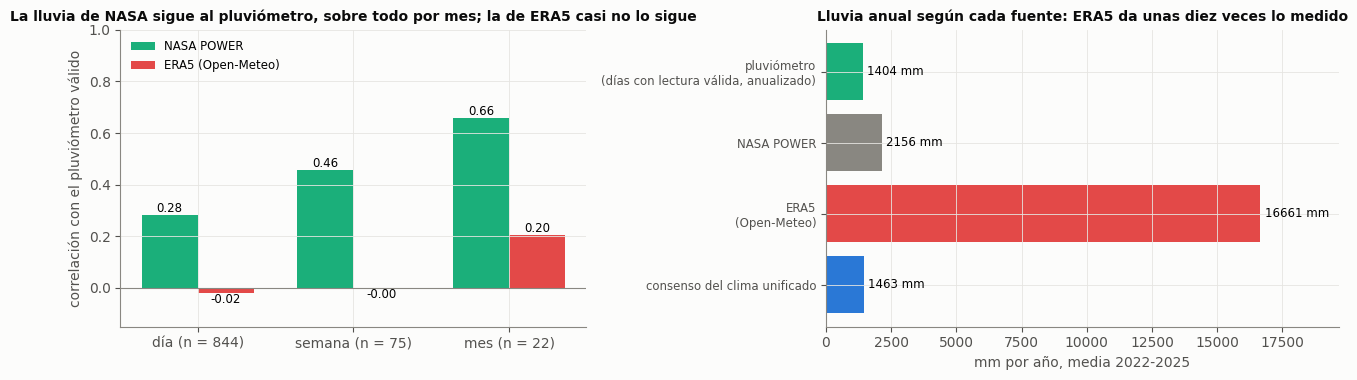

lluvia anual, media 2022-2025 (mm): {'pluviómetro (días con lectura válida, anualizado)': 1404, 'NASA POWER': 2156, 'ERA5 (Open-Meteo)': 16661, 'consenso del clima unificado': 1463}
días con la transición seco → lluvioso, por año: {2010: 4, 2011: 4, 2012: 4, 2013: 0, 2014: 1, 2015: 6, 2016: 7, 2017: 11, 2018: 10, 2019: 14, 2020: 15, 2021: 6, 2022: 1, 2023: 8, 2024: 25, 2025: 1, 2026: 0} | total 117
clima completo: 2010-01-01 a 2026-09-29, 6116 días, 54 columnas


,NASA POWER,ERA5 (Open-Meteo)
día,0.28,-0.02
semana,0.46,-0.00
mes,0.66,0.20


In [11]:
# Clima completo (reanálisis desde 2010 en La Nubia): se valida la lluvia contra el pluviómetro válido.
pv = clima.precipitacion_mm.where(clima.precip_con_estacion.astype(bool))        # pluviómetro IDEAM, solo días válidos
fuentes_ll = {"NASA POWER": cc.lluvia_nasa.reindex(clima.index), "ERA5 (Open-Meteo)": clima.om_precipitation_sum}

def agrega(serie, freq, minimo):
    ok = pv.notna()
    n = ok.resample(freq).sum()
    return serie.where(ok).resample(freq).sum(min_count=1).where(n >= minimo)

ESC = [("día", "D", 1), ("semana", "W", 7), ("mes", "MS", 25)]
R = pd.DataFrame({nom: {etq: agrega(pv, f, mn).corr(agrega(s, f, mn)) for etq, f, mn in ESC} for nom, s in fuentes_ll.items()})
n_val = {etq: int(agrega(pv, f, mn).notna().sum()) for etq, f, mn in ESC}

mm_anio = pd.Series({
    "pluviómetro (días con lectura válida, anualizado)": pv.dropna().loc["2022":"2025"].mean() * 365.25,
    "NASA POWER": fuentes_ll["NASA POWER"].loc["2022":"2025"].mean() * 365.25,
    "ERA5 (Open-Meteo)": fuentes_ll["ERA5 (Open-Meteo)"].loc["2022":"2025"].mean() * 365.25,
    "consenso del clima unificado": clima.precip_consenso_mm.loc["2022":"2025"].mean() * 365.25})

fig, axes = plt.subplots(1, 2, figsize=(13, 3.9), gridspec_kw={"width_ratios": [1, 1.1]})
x = np.arange(len(ESC)); w = .36
for k, (nom, col) in enumerate(zip(R.columns, [AQUA, ROJO])):
    b = axes[0].bar(x + (k - .5) * w, R[nom], w, color=col, label=nom)
    axes[0].bar_label(b, fmt="%.2f", fontsize=8.5)
axes[0].axhline(0, color=MUDO, lw=.8)
axes[0].set_xticks(x, [f"{e[0]} (n = {n_val[e[0]]})" for e in ESC]); axes[0].set_ylim(-.15, 1)
axes[0].set_ylabel("correlación con el pluviómetro válido"); axes[0].legend(loc="upper left", fontsize=8.5)
axes[0].set_title("La lluvia de NASA sigue al pluviómetro, sobre todo por mes; la de ERA5 casi no lo sigue", fontsize=10)
b = axes[1].barh(range(len(mm_anio)), mm_anio.values, color=[AQUA, MUDO, ROJO, AZUL])
axes[1].bar_label(b, fmt="%.0f mm", fontsize=8.5, padding=3)
axes[1].set_yticks(range(len(mm_anio)), [i.replace(" (", "\n(") for i in mm_anio.index], fontsize=8.5); axes[1].invert_yaxis()
axes[1].set_xlim(0, mm_anio.max() * 1.18); axes[1].set_xlabel("mm por año, media 2022-2025")
axes[1].set_title("Lluvia anual según cada fuente: ERA5 da unas diez veces lo medido", fontsize=10)
plt.tight_layout(); plt.show()

ST = cc.seco_a_lluvioso.groupby(cc.index.year).sum().astype(int)
print("lluvia anual, media 2022-2025 (mm):", mm_anio.round(0).astype(int).to_dict())
print("días con la transición seco → lluvioso, por año:", ST.to_dict(), "| total", int(ST.sum()))
print(f"clima completo: {cc.index.min():%Y-%m-%d} a {cc.index.max():%Y-%m-%d}, {len(cc)} días, {cc.shape[1]} columnas")
R.round(2)


## Lectura

**La lluvia de ERA5 es inservible en Manizales y la de NASA solo vale en ventanas largas.**

- **ERA5** da unos 16.660 mm al año en 2022-2025 y una correlación diaria de −0,02 con el pluviómetro válido; en el mes llega solo a 0,20.
- **NASA POWER** da unos 2.160 mm al año (el pluviómetro, en los días con lectura válida, unos 1.400). Su correlación con el pluviómetro es de **0,28 por día, 0,46 por semana y 0,66 por mes**, sobre 844 días, 75 semanas y 22 meses válidos. `calendarios/docs/CLIMA.md` reporta 0,30, 0,52 y 0,80 con otra regla de agregación; el orden y la conclusión son los mismos, y las cifras de aquí se calculan con la regla que se imprime en la celda.
- Por eso toda variable de lluvia del clima completo usa **ventanas de 7 días o más**.
- La transición `seco_a_lluvioso` del clima completo marca 117 días entre 2010 y 2026, muy desigualmente repartidos (25 en 2024, 1 en 2022 y 1 en 2025): es una señal rara, lo que condiciona cualquier prueba que se apoye en ella.

**Qué se encontró con el clima.**
- **Contra el triage total, el entorno general no predice de forma estable.** El barrido del cuaderno 12 (693 pruebas) dio 84 con p < 0,05, cuando el azar daría unas 35, y 34 sobrevivieron al control; casi todas son un solo patrón a rezago 0 (la semana soleada, seca y cálida trae +1-2 %). En la muestra de confirmación se confirmó **1** (el azar daría 0,85): el cambio de radiación a 2 semanas, de +1,4 % a +1,2 %, y +1,0 % con el mes fijo (p = 0,001), que por ser de la misma semana se lee como acceso al hospital y no como contagio.
- **Con el clima completo** (cuaderno 17, 266 pruebas por desenlace): 53 sobreviven contra la IRA de Manizales (2012-2024), 36 contra el triage total (2022-2024) con efectos de **1,5 a 2,4 %**, y **0** contra los ingresos respiratorios del hospital. El clima mueve la IRA de la ciudad, pero sus efectos sobre el total no son los de la IRA: la correlación entre unos y otros es de −0,35 en 266 pares y solo 6 pruebas sobreviven en los dos (cuaderno 17).
- **La sequía de 2026**, frente a lo normal del mes: abril −35 %, mayo −45 %, julio −52 %, y gira a +44 % en agosto; en 4 episodios parecidos con triage las 4 a 8 semanas posteriores quedaron en −0,6 % en el total y −2,1 % en respiratorio (cuaderno 12).
- **Por familias de enfermedad** (cuaderno 19): el clima mueve a las transmisibles de la ciudad (digestiva +15,7 % tras semanas largas sin lluvia fuerte; respiratoria −9,5 % tras una racha seca, a 3 semanas) y ninguna familia llega con fuerza al total del hospital (1-3 %).

---
# 4. Seguridad: delitos y lesiones de MinDefensa

**Qué es.** Delitos registrados por la Policía en Manizales, sumados por día.

- **Publica:** Ministerio de Defensa Nacional, en datos.gov.co:
  - `ntej-qq7v`: lesiones en accidente de tránsito;
  - `uav5-b85g`: homicidio en accidente de tránsito;
  - `jr6v-i33g`: lesiones personales;
  - `m8fd-ahd9`: homicidio;
  - `gepp-dxcs`: violencia intrafamiliar.

  Consulta: `https://www.datos.gov.co/resource/<id>.json?$where=cod_muni='17001'`. Los conjuntos cubren desde 2003; aquí se integran desde 2015.
- **Se rehace con** `python calendarios/seguridad/mindefensa.py`. Solo pide sumas por día (`$group=fecha_hecho`), nunca una fila suelta.
- **Rezago: 2-6 semanas**, publicación mensual.
- **Mide lo denunciado, no lo ocurrido.**

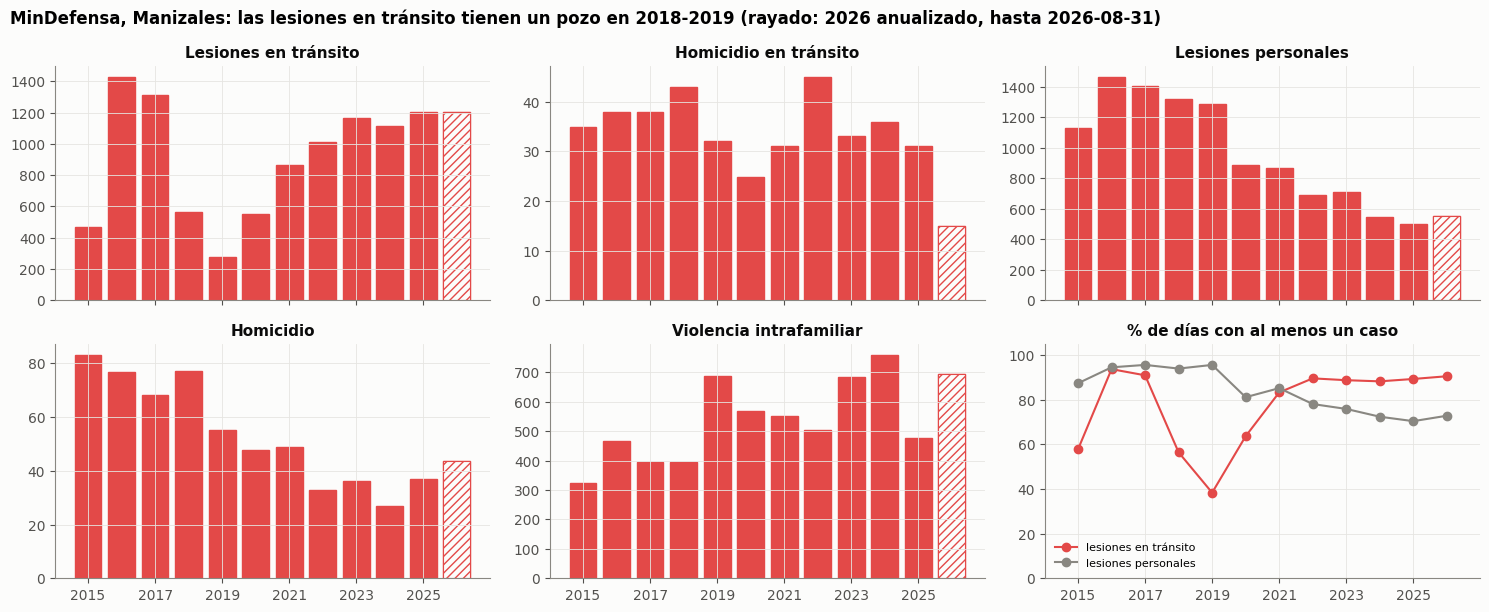

,Lesiones en tránsito,Homicidio en tránsito,Lesiones personales,Homicidio,Violencia intrafamiliar,días con lesión en tránsito (%),días con lesión personal (%)
fecha,,,,,,,
2015,467,35,1132,83,323,58,87
2016,1432,38,1469,77,466,94,95
2017,1313,38,1403,68,394,91,96
2018,563,43,1319,77,395,56,94
2019,279,32,1288,55,688,38,96
2020,550,25,890,48,570,64,81
2021,862,31,870,49,551,83,85
2022,1013,45,690,33,505,90,78
2023,1168,33,711,36,683,89,76


In [12]:
DEL = {"lesiones_transito": "Lesiones en tránsito", "homicidio_transito": "Homicidio en tránsito",
       "lesiones_personales": "Lesiones personales", "homicidio": "Homicidio", "violencia_intrafamiliar": "Violencia intrafamiliar"}
anual_s = seg.groupby(seg.index.year).sum()
dias_s = seg.groupby(seg.index.year).size()
parcial = dias_s.index[dias_s < 365]
fig, axes = plt.subplots(2, 3, figsize=(15, 6.2), sharex=True)
for ax, (c, t) in zip(axes.flat, DEL.items()):
    v = anual_s[c] * 365 / dias_s                  # 2026 anualizado
    ax.bar(v.index, v, color=[SUP if a in parcial else ROJO for a in v.index], edgecolor=ROJO, hatch=None)
    for a in parcial:
        ax.bar(a, v[a], color=SUP, edgecolor=ROJO, hatch="////", lw=.8)
    ax.set_title(t)
dias_con = (seg > 0).groupby(seg.index.year).mean() * 100
axes.flat[5].plot(dias_con.index, dias_con.lesiones_transito, "o-", color=ROJO, label="lesiones en tránsito")
axes.flat[5].plot(dias_con.index, dias_con.lesiones_personales, "o-", color=MUDO, label="lesiones personales")
axes.flat[5].set_title("% de días con al menos un caso"); axes.flat[5].legend(fontsize=8, loc="lower left"); axes.flat[5].set_ylim(0, 105)
for ax in axes[-1]:
    ax.set_xticks(range(2015, 2027, 2))
fig.suptitle(f"MinDefensa, Manizales: las lesiones en tránsito tienen un pozo en 2018-2019 (rayado: {', '.join(map(str, parcial))} anualizado, hasta {seg.index.max():%Y-%m-%d})",
             fontweight="bold", x=.01, ha="left")
plt.tight_layout(); plt.show()
out = anual_s.astype(int).copy(); out.columns = [DEL[c] for c in out.columns]
out["días con lesión en tránsito (%)"] = dias_con.lesiones_transito.round(0).astype(int)
out["días con lesión personal (%)"] = dias_con.lesiones_personales.round(0).astype(int)
out

## Lectura

**Las lesiones en tránsito tienen dos regímenes de registro, no uno.**

| | 2015 | 2016 | 2017 | 2018 | 2019 | 2020 | 2021 | 2022-2025 |
|---|---|---|---|---|---|---|---|---|
| Lesiones en tránsito | 467 | 1.432 | 1.313 | 563 | **279** | 550 | 862 | 1.013-1.206 |
| Días con al menos un caso (%) | 58 | 94 | 91 | 56 | **38** | 64 | 83 | 88-90 |

- El «escalón de 2019» que a primera vista sugiere la serie es en realidad un **pozo de 2018-2019** entre dos mesetas. Lo delata el porcentaje de días con algún caso, que se hunde al 38 %: menos días con registro, no menos accidentes (inferido).
- **Lesiones personales cae un 62 %** de 2018 (1.319) a 2025 (501), y los días con algún caso pasan del 94 % (2018) al 70 % (2025), última columna de la tabla. Tampoco parece la realidad.
- **Violencia intrafamiliar salta en 2019** (395 → 688) y vuelve a caer en 2025 (760 → 475).
- Homicidio en tránsito lleva 10 casos en 2026; su conjunto de datos llega hasta julio (`calendarios/docs/FUENTES_EXTERNAS.md`).
- Hay otras series del mismo origen que no se integraron, como el hurto a personas (`4rxi-8m8d`).

**Qué se encontró con ella.**
- **El calendario mueve la violencia de la ciudad** (Poisson, 2015-2026 sin cuarentenas): lesiones personales **×1,78 en domingo, ×1,32 en festivo y ×1,96 en noche festiva**; homicidios ×2,11 en domingo y ×2,02 en noche festiva; el tránsito baja en festivo (×0,72). La violencia intrafamiliar tiene otro calendario: quincena ×1,20 y receso escolar ×0,83 (cuaderno 09).
- Las lesiones personales de la Policía suben **+161 % en velitas, +120 % el 8 de diciembre, +54 % el 25 y +201 % el 1 de enero** (cuaderno 08).
- **El tránsito de la ciudad no se mueve con el SOAT del SES** (r = 0,01), salvo en la Feria (cuaderno 07).

**Qué puede sostener.** Comparaciones dentro de un régimen estable: 2021-2026 en tránsito, y la forma semanal y festiva de las lesiones personales.

**Qué no.** Cruzar 2018-2019, ni leer la caída de las lesiones personales como menos violencia.

---
# 5. La red de salud: el asegurador de cada triage

**Qué es.** El triage del SES por **entidad administradora**: la EPS, la aseguradora SOAT, la ARL, o «particular». No es una fuente externa, pero es la que mide la **red de salud**, que resultó la familia de mayor efecto sobre el volumen.

- **Origen:** base del hospital, día × hora × entidad, solo conteos agregados.
- Los grupos salen de `extraccion/entidades.py`; la clasificación es un borrador sujeto a revisión.
- **Rezago:** ninguno, hasta la última extracción.

Se dibuja la **cuota** de cada grupo, no su conteo: el conteo de un subgrupo repite el ciclo del total y no dice nada. Las líneas punteadas son hechos documentados: la intervención de Nueva EPS por la Supersalud (2024-04-03) y los cierres de servicios de Avidanti (2025-08-21) y Santa Sofía (2025-12-01).

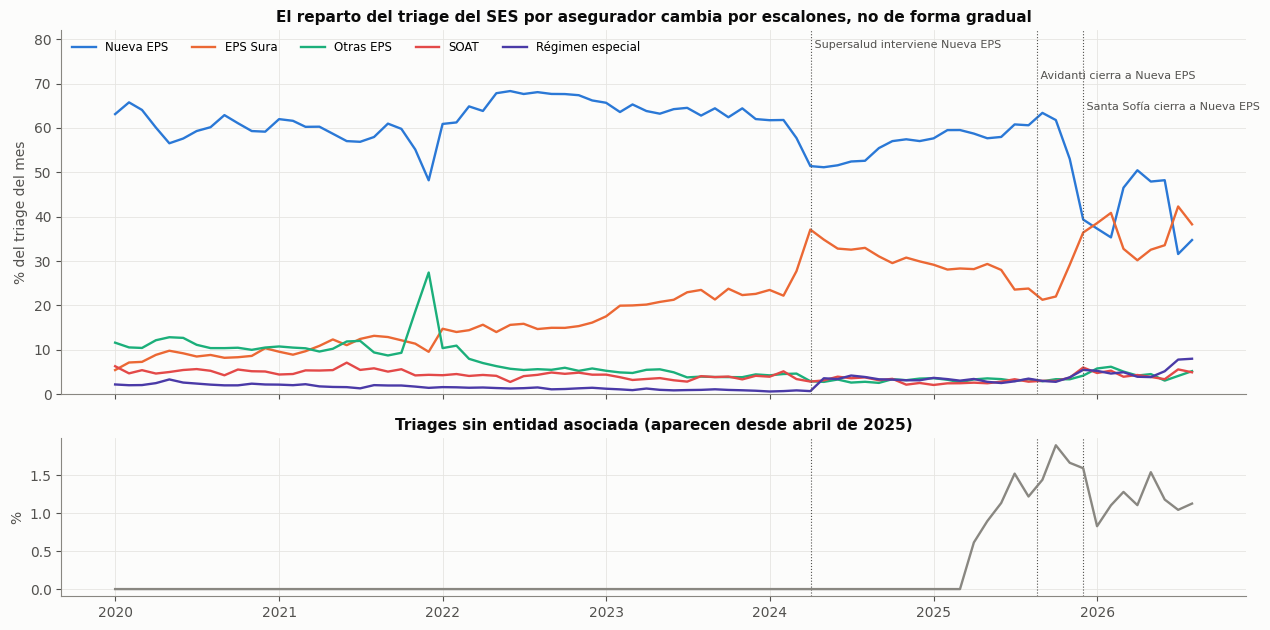

triages en el archivo por entidad hasta 2026-09-21: 433,531; en el diario: 433,392 (diferencia +139)
primer mes con triages sin entidad: 2025-04
el archivo por entidad llega al 2026-09-28; los días posteriores al diario suman 1,195


dia,2021-11,2021-12,2022-01,2024-02,2024-03,2024-04,2025-10,2025-11,2025-12,2026-02,2026-03,2026-06,2026-07,2026-08
grupo,,,,,,,,,,,,,,
nueva_eps,55.2,48.2,60.9,61.8,57.7,51.4,61.8,53.0,39.4,35.3,46.5,48.2,31.6,34.7
sura_eps,11.4,9.6,14.8,22.2,27.7,37.1,22.0,29.2,36.4,40.9,32.8,33.6,42.3,38.3
otra_eps,18.7,27.4,10.4,4.6,4.6,2.9,3.4,3.4,4.2,6.2,5.1,3.1,4.1,5.2
sin_entidad,0.0,0.0,0.0,0.0,0.0,0.0,1.9,1.7,1.6,1.1,1.3,1.2,1.0,1.1


grupo,nueva_eps,sura_eps,otra_eps,soat_aseguradora,regimen_especial,particular,arl,prepagada,sin_entidad
dia,,,,,,,,,
2020,61.3,8.1,11.0,5.3,2.3,2.8,1.5,2.5,0.0
2021,57.6,11.3,13.2,5.2,1.8,3.2,1.3,1.8,0.0
2022,66.1,15.0,6.8,4.3,1.4,1.1,0.9,1.8,0.0
2023,63.9,21.4,4.6,3.7,1.0,0.7,0.9,2.0,0.0
2024,55.4,30.7,3.3,3.4,2.6,0.8,0.9,1.4,0.0
2025,58.0,27.0,3.3,3.0,3.3,0.6,0.8,1.2,1.0
2026,41.7,36.0,4.6,4.5,5.7,0.7,1.3,2.4,1.2


In [13]:
GRUPOS = {"nueva_eps": ("Nueva EPS", AZUL), "sura_eps": ("EPS Sura", NARANJA), "otra_eps": ("Otras EPS", AQUA),
          "soat_aseguradora": ("SOAT", ROJO), "regimen_especial": ("Régimen especial", VIOLETA)}
g = ent.pivot_table(index="dia", columns="grupo", values="n", aggfunc="sum").fillna(0).loc[:"2026-08-31"]
cuota = 100 * g.resample("MS").sum().pipe(lambda d: d.div(d.sum(axis=1), axis=0))
fig, axes = plt.subplots(2, 1, figsize=(13, 6.4), sharex=True, gridspec_kw={"height_ratios": [2.3, 1]})
for c, (t, col) in GRUPOS.items():
    axes[0].plot(cuota.index, cuota[c], color=col, lw=1.7, label=t)
for i, (f, t) in enumerate([("2024-04-03", "Supersalud interviene Nueva EPS"), ("2025-08-21", "Avidanti cierra a Nueva EPS"),
                            ("2025-12-01", "Santa Sofía cierra a Nueva EPS")]):
    for ax in axes:
        ax.axvline(pd.Timestamp(f), color=TINTA2, lw=.8, ls=":")
    axes[0].text(pd.Timestamp(f), 78 - 7 * i, " " + t, fontsize=8, color=TINTA2)
axes[0].set_ylabel("% del triage del mes"); axes[0].set_title("El reparto del triage del SES por asegurador cambia por escalones, no de forma gradual")
axes[0].legend(loc="upper left", ncol=5, fontsize=8.5); axes[0].set_ylim(0, 82)
axes[1].plot(cuota.index, cuota["sin_entidad"], color=MUDO, lw=1.7)
axes[1].set_ylabel("%"); axes[1].set_title("Triages sin entidad asociada (aparecen desde abril de 2025)")
plt.tight_layout(); plt.show()
comun = ent[ent.dia <= tri.dia.max()].n.sum()
print(f"triages en el archivo por entidad hasta {tri.dia.max():%Y-%m-%d}: {comun:,}; en el diario: {tri.triages.sum():,} "
      f"(diferencia {comun - tri.triages.sum():+,})")
print(f"primer mes con triages sin entidad: {cuota.index[cuota.sin_entidad > 0][0]:%Y-%m}")
print(f"el archivo por entidad llega al {ent.dia.max():%Y-%m-%d}; los días posteriores al diario suman {ent[ent.dia > tri.dia.max()].n.sum():,}")
MESES = ["2021-11-01", "2021-12-01", "2022-01-01", "2024-02-01", "2024-03-01", "2024-04-01", "2025-10-01", "2025-11-01",
         "2025-12-01", "2026-02-01", "2026-03-01", "2026-06-01", "2026-07-01", "2026-08-01"]
display(cuota.loc[MESES, ["nueva_eps", "sura_eps", "otra_eps", "sin_entidad"]].round(1).rename(index=lambda d: f"{d:%Y-%m}").T)
ga = ent.groupby([ent.dia.dt.year, "grupo"]).n.sum().unstack(fill_value=0)
(100 * ga.div(ga.sum(axis=1), axis=0)).round(1)[["nueva_eps", "sura_eps", "otra_eps", "soat_aseguradora", "regimen_especial",
                                                  "particular", "arl", "prepagada", "sin_entidad"]]

## Lectura

**El reparto entre aseguradores cambia por escalones, no de forma gradual.**

| Mes | 2021-11 | 2021-12 | 2024-02 | 2024-04 | 2025-10 | 2025-12 | 2026-03 | 2026-06 | 2026-07 |
|---|---|---|---|---|---|---|---|---|---|
| Nueva EPS % | 55,2 | 48,2 | 61,8 | 51,4 | 61,8 | **39,4** | 46,5 | 48,2 | **31,6** |
| EPS Sura % | 11,4 | 9,6 | 22,2 | **37,1** | 22,0 | 36,4 | 32,8 | 33,6 | 42,3 |
| Otras EPS % | 18,7 | **27,4** | 4,6 | 2,9 | 3,4 | 4,2 | 5,1 | 3,1 | 4,1 |

- **Diciembre de 2021:** «otras EPS» sube al 27 %. Coincide con la liquidación de Medimás (cuaderno 07).
- **Entre febrero y abril de 2024** Sura pasa del 22 al 37 %. En abril la Supersalud interviene Nueva EPS. El escalón de abril de 2024 fue de Sura (+40 triages por día) y no de Nueva EPS (−0,2) (cuaderno 18). El 28 de febrero de 2024 el SES había anunciado que no atendería en urgencias a usuarios de Salud Total y Sanitas, un corte real pero de solo 4 a 6 triages por día (informe del contexto oficial de los picos, en `calendarios/docs/`).
- **Noviembre y diciembre de 2025:** Nueva EPS cae del 62 al 39 %. Se recupera en parte en marzo de 2026 y vuelve a caer en julio de 2026 (32 %).
- Por año, Nueva EPS pasa del 61,3 % (2020) al 41,7 % (2026) y Sura del 8,1 % al 36,0 %. Régimen especial sube del 2,6 % (2024) al 5,7 % (2026).

**Un escalón de calidad: desde 2025 aparecen triages sin entidad asociada.** Eran 0 hasta 2024; son el 1,0 % en 2025 y el 1,2 % en 2026, y el primer mes con ellos es abril de 2025. Es poco, pero es un cambio de registro.

**Coherencia con el diario.** Hasta el 2026-09-21, el archivo por entidad suma 433.531 triages y el diario 433.392: 139 más. El archivo por entidad llega además al 2026-09-28.

**Qué se encontró con ella.** Es la variable de mayor efecto sobre el nivel. Nueva EPS pasa de 115,8 a 72,2 triages por día entre 2025 y 2026 (**−38 %**), con desplomes a mediados de noviembre de 2025 y en julio de 2026; esos escalones explican las semanas más bajas del análisis semanal (cuadernos 06 y 07). Su efecto es sobre el *volumen*, no sobre el porqué de un pico.

**Límite.** La cuota dice cómo se reparte la demanda, no por qué. Las fechas de suspensión y reanudación de servicios entre el SES y Nueva EPS no existen como dato (sección 8).

## 5.1 El panel de las EPS: afiliados, tamaño y medidas de la Supersalud

Tres fuentes públicas describen la red desde fuera del hospital.

- **Afiliación mensual de MinSalud** (EPS × municipio, julio de 2025 a agosto de 2026): permite dividir el triage de cada EPS entre sus afiliados y separar «perdió afiliados» de «sus afiliados dejaron de venir».
- **BDUA de ADRES** (afiliados por EPS, municipio, edad, sexo y régimen): es el tamaño de cada EPS en un día, pero solo existe la foto del mes, sin histórico; cada mes sin guardar se pierde.
- **Medidas de la Supersalud:** las resoluciones con fecha que intervienen a una EPS. Solo se publican las medidas vigentes.

La figura de la izquierda compara, como índice, los afiliados y el triage por día de Nueva EPS y de Sura en Manizales. La de la derecha pone las resoluciones de la Supersalud sobre Nueva EPS encima de su triage.

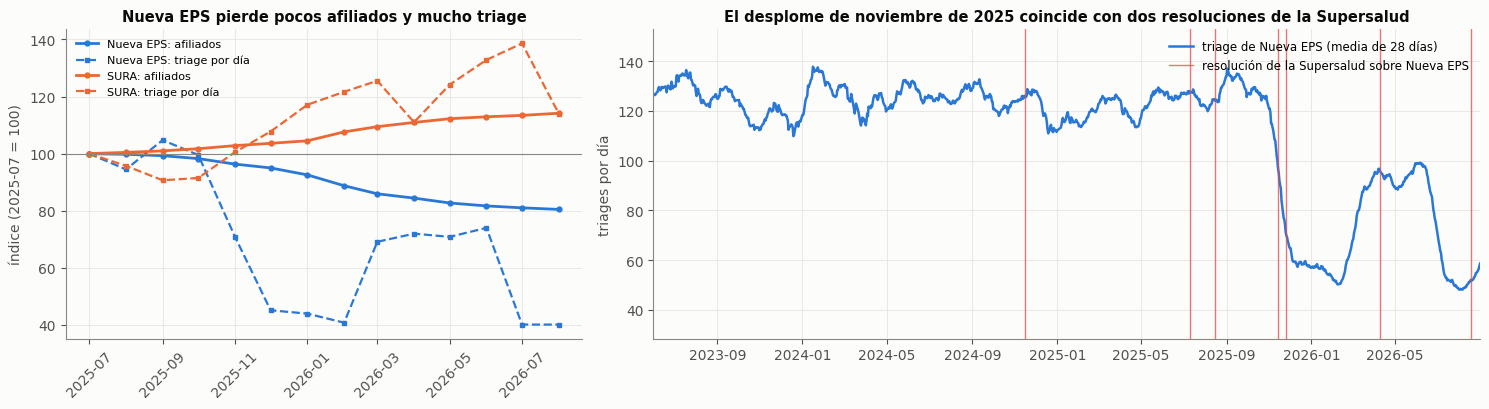

BDUA, afiliados de Caldas (corte 2026-10-02): {'contributivo': 473394, 'subsidiado': 435507}
resoluciones sobre Nueva EPS: ['2024-11-15', '2025-07-10', '2025-08-15', '2025-11-14', '2025-11-25', '2026-04-10', '2026-08-18']
                                                  primera     última  resoluciones
eps                                                                               
ASMET SALUD EPS S.A.S.                         2023-05-11 2026-07-10            12
CAPRESOCA EPS                                  2024-10-07 2026-07-06             6
COOSALUD EPS                                   2024-11-22 2026-08-27            12
EMSSANAR EPS SAS                               2022-02-02 2026-06-02            11
FAMISANAR EPS                                  2023-09-15 2026-08-28            10
NUEVA EPS                                      2024-11-15 2026-08-18             7
S.O.S. EPS "SERVICIO OCCIDENTAL DE SALUD S.A." 2024-04-10 2026-08-21            10


regimen,contributivo,subsidiado,total
ent_nombre,,,
EPS SURAMERICANA S.A.,136899,0,136899
SALUD TOTAL ENTIDAD PROMOTORA DE SALUD DEL,90614,0,90614
NUEVA EPS S.A.,45651,29358,75009
ENTIDAD PROMOTORA DE SALUD SANITAS S.A.S.,47486,0,47486
SALUD TOTAL ENTIDAD PROMOTORA DE SALUD DEL,0,33108,33108
EPS SURAMERICANA S.A. -CM,0,23479,23479


,afiliados 2025-07,afiliados 2026-08,triage/día 2025-07,triage/día 2026-08,cambio afiliados %,cambio triage %,cambio del uso por afiliado %
Nueva EPS,112573.0,90585.0,128.8,51.7,-19.5,-59.9,-50.1
SURA,140195.0,160024.0,50.0,57.0,14.1,14.0,-0.1


In [14]:
# Panel de aseguradores: afiliados (MinSalud), tamaño de cada EPS (BDUA) y resoluciones de la Supersalud sobre Nueva EPS.
AF = AFIL[list(MAPA_EPS)].rename(columns=MAPA_EPS)
uso = g.resample("MS").mean()[["nueva_eps", "sura_eps"]].rename(columns={"nueva_eps": "Nueva EPS", "sura_eps": "SURA"})
m0, m1 = AF.index.min(), AF.index.max()
cmp = pd.DataFrame({f"afiliados {m0:%Y-%m}": AF.loc[m0, ["Nueva EPS", "SURA"]], f"afiliados {m1:%Y-%m}": AF.loc[m1, ["Nueva EPS", "SURA"]],
                    f"triage/día {m0:%Y-%m}": uso.loc[m0], f"triage/día {m1:%Y-%m}": uso.loc[m1]})
cmp["cambio afiliados %"] = 100 * (cmp.iloc[:, 1] / cmp.iloc[:, 0] - 1)
cmp["cambio triage %"] = 100 * (cmp.iloc[:, 3] / cmp.iloc[:, 2] - 1)
cmp["cambio del uso por afiliado %"] = 100 * ((cmp.iloc[:, 3] / cmp.iloc[:, 1]) / (cmp.iloc[:, 2] / cmp.iloc[:, 0]) - 1)

# resoluciones de la Supersalud (tabla limpia de la captura; sin datos de personas)
f_med = sorted(glob.glob(str(CAL / "capturas/medidas/*/CTFT21-Listado*EPS.csv")))[-1]
med = pd.read_csv(f_med); c_res = next(c for c in med.columns if c.upper().startswith("RESOLU"))
MES_N = {"enero": 1, "febrero": 2, "marzo": 3, "abril": 4, "mayo": 5, "junio": 6, "julio": 7, "agosto": 8, "septiembre": 9, "octubre": 10, "noviembre": 11, "diciembre": 12}
ev = []
for _, r in med.iterrows():
    for d_, mes_, a_ in re.findall(r"(\d{1,2}) de (\w+) del? (\d{4})", str(r[c_res]).lower()):
        if mes_ in MES_N:
            ev.append({"eps": r["ENTIDAD"].split("\n")[0].strip(), "fecha": pd.Timestamp(int(a_), MES_N[mes_], int(d_))})
EV = pd.DataFrame(ev).drop_duplicates().sort_values(["eps", "fecha"])
ne_res = EV[EV.eps.str.upper().str.contains("NUEVA")].fecha

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 1.6]})
for c, col in zip(["Nueva EPS", "SURA"], [AZUL, NARANJA]):
    axes[0].plot(AF.index, 100 * AF[c] / AF[c].iloc[0], "-o", ms=3.5, lw=2, color=col, label=f"{c}: afiliados")
    axes[0].plot(AF.index, 100 * uso.loc[AF.index, c] / uso.loc[m0, c], "--s", ms=3.5, lw=1.6, color=col, label=f"{c}: triage por día")
axes[0].axhline(100, color=MUDO, lw=.8); axes[0].set_ylabel(f"índice ({m0:%Y-%m} = 100)")
axes[0].set_title("Nueva EPS pierde pocos afiliados y mucho triage", fontsize=10.5); axes[0].legend(fontsize=8)
axes[0].tick_params(axis="x", rotation=45)
roll = g["nueva_eps"].rolling(28, center=True, min_periods=14).mean()
axes[1].plot(roll.index, roll, color=AZUL, lw=1.8, label="triage de Nueva EPS (media de 28 días)")
for k, d_ in enumerate(ne_res):
    axes[1].axvline(d_, color=ROJO, lw=1, alpha=.75, label="resolución de la Supersalud sobre Nueva EPS" if k == 0 else None)
axes[1].set_xlim(pd.Timestamp("2023-06-01"), g.index[-1]); axes[1].set_ylabel("triages por día"); axes[1].legend(loc="upper right", fontsize=8.5)
axes[1].set_title("El desplome de noviembre de 2025 coincide con dos resoluciones de la Supersalud", fontsize=10.5)
plt.tight_layout(); plt.show()

b = pd.concat(bdua.values()); b_m = b[b.mnc_nombre.str.upper().str.contains("MANIZALES")]
top = b_m.groupby(["ent_nombre", "regimen"]).afiliados.sum().unstack(fill_value=0); top["total"] = top.sum(axis=1)
print("BDUA, afiliados de Caldas (corte " + str(b.corte_datos_gov.iloc[0]) + "):", {r: int(d_.afiliados.sum()) for r, d_ in bdua.items()})
print("resoluciones sobre Nueva EPS:", [d_.date().isoformat() for d_ in ne_res])
print(EV.groupby("eps").fecha.agg(["min", "max", "count"]).rename(columns={"min": "primera", "max": "última", "count": "resoluciones"}).to_string())
display(top.sort_values("total", ascending=False).head(6).astype(int).rename(index=lambda s: s[:42]))
cmp.round(1)


## Lectura

**La caída de Nueva EPS es sobre todo de acceso, no de traslado de afiliados.**

- De julio de 2025 a agosto de 2026, Nueva EPS pierde **19,5 %** de sus afiliados en Manizales (de 112.573 a 90.585) y **59,9 %** de su triage por día (de 128,8 a 51,7): el uso por afiliado cae **50,1 %**. Sura gana 14,1 % de afiliados y 14,0 % de triage, con el uso por afiliado igual (−0,1 %). Que Nueva EPS pierda mucho más triage que afiliados, y que Sura no absorba esa diferencia, indica una barrera de acceso y no que los pacientes se hayan pasado a otra aseguradora.
- Cuando Nueva EPS cae, el resto compensa poco: en noviembre de 2025, el 16 % de −70 triages por día (el total cae un 28 %); en julio de 2026, el 11 % (el total cae un 19 %) (cuaderno 18). Con otra ventana la cifra es del 13 % y el 22 % (cuaderno 01): depende de la ventana.
- **La Supersalud tiene 7 resoluciones con fecha sobre Nueva EPS**, entre el 2024-11-15 y el 2026-08-18 en la tabla vigente. Las del **14 y el 25 de noviembre de 2025 coinciden con el escalón del 15 de noviembre**. Las caídas de marzo y julio de 2026 no tienen resolución cerca: probablemente son decisiones de contratación entre el SES y la aseguradora, que no son públicas (sección 8).
- **BDUA, corte del 2026-10-02:** 473.394 afiliados en Caldas en el contributivo y 435.507 en el subsidiado. En Manizales, Sura (136.899 en el contributivo) y Salud Total (90.614) son las mayores; Nueva EPS suma 75.009 entre los dos regímenes (45.651 y 29.358), sin contar su variante de convenio.
- **Siete EPS de la región tienen medida de la Supersalud**; cada captura semanal añade las que entren o salgan.

**Qué incorporó esto al análisis.** Seis variables de red entran al modelo: el peso de Nueva EPS y de Sura en 28 días, el cambio de Nueva EPS y del resto en 28 días, el índice de Herfindahl y una marca de resolución de la Supersalud sobre Nueva EPS en los últimos 30 días (cuaderno 18).

**Límites.** Son variables internas que describen la red, pero no la anticipan. La afiliación mensual y el uso por afiliado tienen solo 14 meses de historia; se acumulan con la captura semanal. Sanitas aparece como intervenida en el portal FENIX y no en el Excel de medidas vigentes que usa el repositorio: la discrepancia no está resuelta.

---
# 6. Ambiente y catástrofes: ENSO, sismos y desastres

**ENSO.** El índice ONI de la NOAA (anomalía de la temperatura del mar en la región Niño 3.4, trimestres móviles) sustituye los periodos de El Niño y La Niña escritos a mano. Cubre 1950-2026 con un mes de rezago; el episodio abierto al final de la serie se marca «en curso».

**Sismos.** El catálogo USGS, a 150 km de Manizales, es la vía automatizable. El catálogo del Servicio Geológico Colombiano no sirve para este fin: su interfaz web no filtra bien, el histórico CATS termina en 2020-12-30 y su servicio FDSN responde 404 a toda consulta de eventos.

**Desastres.** Una lista escrita a mano de 17 filas (deslizamientos, vendavales, actividad del Nevado del Ruiz, el terremoto de 2026), cada una con su URL y su calidad de dato. La alternativa oficial, los consolidados de emergencias de la UNGRD, registra solo 80 eventos de Manizales entre 2019 y 2025 (39 en 2019, 4 en 2025), porque son emergencias reportadas para pedir apoyo y no un censo.

La figura pone las tres series en la misma línea de tiempo.

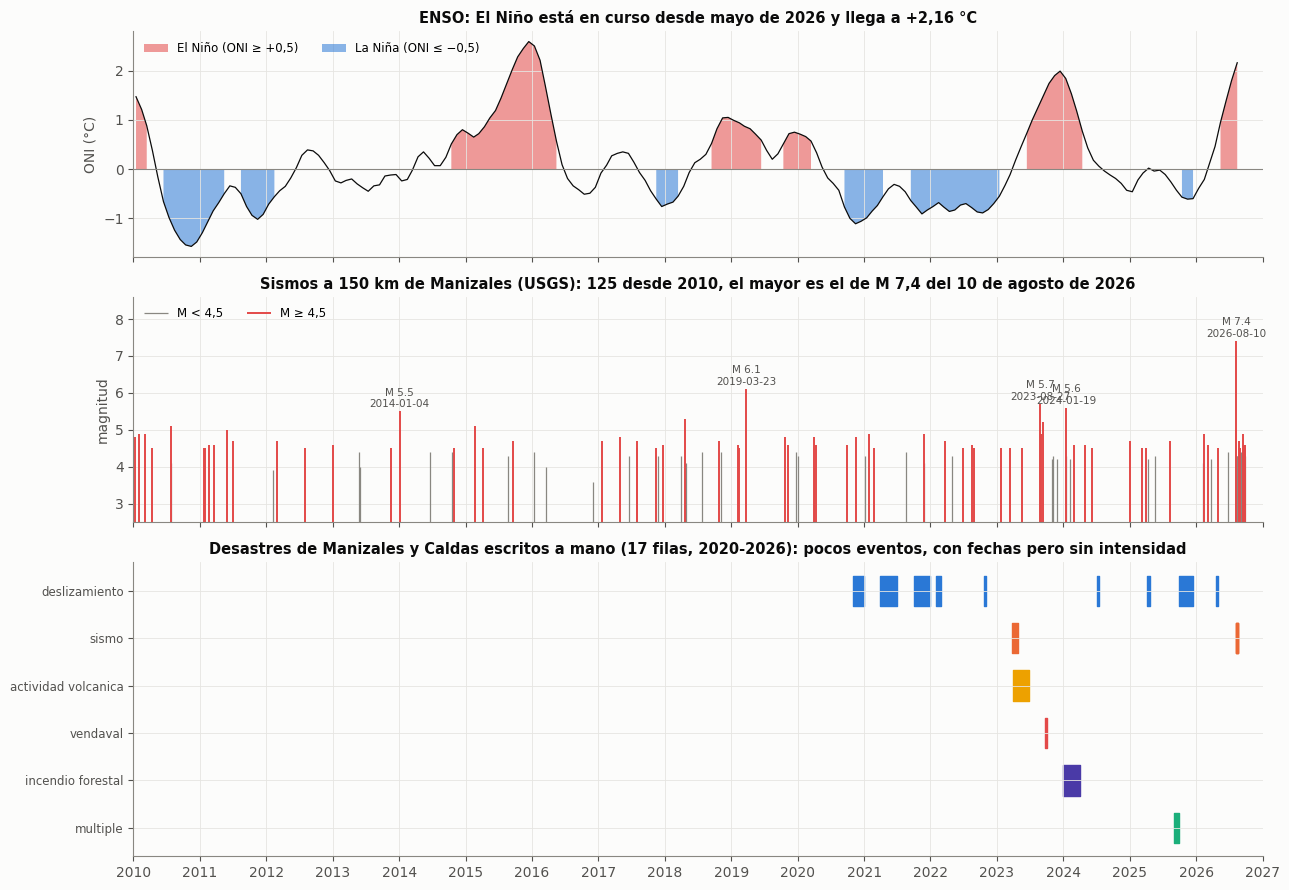

sismos M ≥ 4,5 en el archivo: 74 | entre 2012 y 2024: 43 | M ≥ 3 a menos de 100 km desde 2020: 27
episodios ENSO desde 2012 (meses consecutivos con la misma fase):


,fase,inicio,meses
0,la_nina,2012-01,2
1,el_nino,2014-10,20
2,la_nina,2017-11,5
3,el_nino,2018-09,10
4,el_nino,2019-10,6
5,la_nina,2020-09,8
6,la_nina,2021-09,17
7,el_nino,2023-06,11
8,el_nino,2026-05,4


In [15]:
# ENSO (ONI), sismos (USGS, 150 km de Manizales) y desastres de Manizales, en la misma línea de tiempo.
lat0, lon0 = 5.07, -75.51
sis["km"] = np.hypot((sis.latitude - lat0) * 111, (sis.longitude - lon0) * 111 * np.cos(np.radians(lat0)))
o = oni[oni.fecha >= "2010"]
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True, gridspec_kw={"height_ratios": [1.15, 1.15, 1.5]})
axes[0].plot(o.fecha, o.oni, color=TINTA, lw=.9)
axes[0].fill_between(o.fecha, o.oni, 0, where=o.oni >= .5, color=ROJO, alpha=.55, lw=0, label="El Niño (ONI ≥ +0,5)")
axes[0].fill_between(o.fecha, o.oni, 0, where=o.oni <= -.5, color=AZUL, alpha=.55, lw=0, label="La Niña (ONI ≤ −0,5)")
axes[0].axhline(0, color=MUDO, lw=.8); axes[0].set_ylabel("ONI (°C)"); axes[0].legend(loc="upper left", fontsize=8.5, ncol=2)
axes[0].set_title("ENSO: El Niño está en curso desde mayo de 2026 y llega a +2,16 °C", fontsize=10.5)
fu = sis.mag >= 4.5
axes[1].vlines(sis.fecha[~fu], 2.5, sis.mag[~fu], color=MUDO, lw=.9, label="M < 4,5")
axes[1].vlines(sis.fecha[fu], 2.5, sis.mag[fu], color=ROJO, lw=1.4, label="M ≥ 4,5")
for _, r in sis[sis.mag >= 5.5].iterrows():
    axes[1].annotate(f"M {r.mag:.1f}\n{r.fecha:%Y-%m-%d}", (r.fecha, r.mag), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=7.5, color=TINTA2)
axes[1].set_ylim(2.5, 8.6); axes[1].set_ylabel("magnitud"); axes[1].legend(loc="upper left", fontsize=8.5, ncol=2)
axes[1].set_title(f"Sismos a 150 km de Manizales (USGS): {len(sis)} desde 2010, el mayor es el de M 7,4 del 10 de agosto de 2026", fontsize=10.5)
d_ = desastres.assign(i=pd.to_datetime(desastres.fecha_inicio), f=pd.to_datetime(desastres.fecha_fin))
tipos = list(d_.tipo_evento.unique())
for k, t in enumerate(tipos):
    for _, r in d_[d_.tipo_evento == t].iterrows():
        dur = max((r.f - r.i).days, 12)
        axes[2].broken_barh([(mdates.date2num(r.i), dur)], (k - .32, .64), color=[AZUL, NARANJA, AMARILLO, ROJO, VIOLETA, AQUA, VERDE][k % 7])
axes[2].set_yticks(range(len(tipos)), [t.replace("_", " ") for t in tipos], fontsize=8.5); axes[2].invert_yaxis()
axes[2].set_title(f"Desastres de Manizales y Caldas escritos a mano ({len(d_)} filas, 2020-2026): pocos eventos, con fechas pero sin intensidad", fontsize=10.5)
axes[2].xaxis_date(); axes[2].xaxis.set_major_locator(mdates.YearLocator(1)); axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[2].set_xlim(mdates.date2num(pd.Timestamp("2010-01-01")), mdates.date2num(pd.Timestamp("2027-01-01")))
plt.tight_layout(); plt.show()

fases = oni[oni.fecha >= "2012"].assign(fase_=lambda d_: d_.fase.str.replace("_en_curso", ""))
grp = (fases.fase_ != fases.fase_.shift()).cumsum()
epi = fases.groupby(grp).agg(fase=("fase_", "first"), inicio=("fecha", "min"), meses=("fecha", "size"))
epi = epi[epi.fase != "neutral"]
print("sismos M ≥ 4,5 en el archivo:", int(fu.sum()), "| entre 2012 y 2024:", int((fu & sis.fecha.between('2012-01-01', '2024-12-31')).sum()),
      "| M ≥ 3 a menos de 100 km desde 2020:", int(((sis.mag >= 3) & (sis.km <= 100) & (sis.fecha >= '2020-01-01')).sum()))
print("episodios ENSO desde 2012 (meses consecutivos con la misma fase):")
epi.assign(inicio=epi.inicio.dt.strftime("%Y-%m")).reset_index(drop=True)


## Lectura

- **El Niño está en curso y es fuerte:** el ONI de julio-septiembre de 2026 es +2,16 °C. Desde 2012 el archivo tiene episodios de El Niño que empiezan en 2014-10 (20 meses), 2018-09, 2019-10, 2023-06 y 2026-05 (en curso), y de La Niña en 2017-11, 2020-09 y 2021-09 (17 meses). Dentro del periodo con triage hay un episodio completo de El Niño, el de 2023-2024, y el de 2026 todavía abierto.
- **Los sismos son frecuentes y casi todos pequeños para el hospital:** 125 desde 2010, 74 de magnitud 4,5 o más (43 entre 2012 y 2024) y 27 de magnitud 3 o más a menos de 100 km desde 2020. El único de magnitud extrema es el del **10 de agosto de 2026, M 7,4**, con epicentro en San José del Palmar (Chocó), sentido en Manizales; la revisión estructural del SES halló daños menores sin afectación estructural (lista de desastres).
- **Los desastres escritos a mano son pocos y de fecha, no de intensidad:** 9 confirmados, 4 por verificar, 2 con fecha aproximada y 2 confirmados con cifras en actualización. Las temporadas de lluvia, la alerta naranja del Ruiz (2023-03-30 a 2023-06-27) y la temporada de incendios de 2024 duran semanas o meses; el terremoto, un día.

**Qué se encontró con ellos.**
- **ENSO:** El Niño calienta Manizales (ENSO → temperatura **r = +0,49**, cuaderno 09). Con el ONI de dos meses antes como estado, **La Niña sube la enfermedad de la ciudad** (violencias +0,35, salud mental +0,31 y varicela +0,38 desviaciones típicas) y **El Niño se asocia con +3,6 % de triage** (p < 0,001); pero ese resultado descansa en **un solo episodio dentro de la ventana del hospital** (2023-2024), que coincide con el año de mayor volumen y con la entrada de Sura, y puede explicar la firma del «día soleado» de 2022-2024 que desaparece en 2025 (cuaderno 20). Por eso se escribió una predicción prospectiva antes de ver el desenlace: del 2026-10-04 al 2026-12-26, el triage real superará a la mediana de la combinación congelada, que no usa ENSO, en un +2 % o más de media; si no lo hace, la hipótesis se rechaza.
- **Sismos:** con 40 episodios de sismo fuerte (M 4,5 o más a menos de 150 km), **no mueven ni a la ciudad ni al hospital** (cuaderno 20); es un resultado negativo con muestra. El terremoto del 10 de agosto de 2026 es la excepción: el triage baja **−50 % el día del sismo, −26 % la primera semana y −7 % los días 8 a 21** con el método semanal (cuaderno 06); al comparar el episodio con las 8 semanas previas, −48,7 % el día 0, −22,3 % los días 1-7 y −4,6 % los días 8-21 (cuaderno 20).
- **Deslizamientos:** nada medible en el triage (cuaderno 06).

**Límite.** El catálogo USGS mide la magnitud en el origen, no si el sismo se sintió. La ceniza del Ruiz no se puede medir: solo hay 4 episodios y se necesitaría el PM10 de la red de calidad del aire de la Universidad Nacional (sección 8).

---
# 7. Calendario, eventos y fiestas de los municipios

## 7.1 El calendario de Colombia

**Qué es.** Una fila por día con festivos, puentes, quincena, vacaciones escolares, Semana Santa y temporadas. Es el **control** del proyecto, no el producto.
- Los festivos salen de la librería `holidays`, con los festivos de ley trasladados al lunes.
- Semana Santa sale de la fecha de Pascua.
- **Las vacaciones escolares y el regreso a clases del calendario general son reglas fijas del programa**, no el calendario oficial de la Secretaría de Educación. Para los recesos oficiales de Manizales hay una tabla aparte (`calendario_escolar_manizales.csv`, 29 filas de 2021 a 2026: 12 de fin de año, 6 de mitad de año, 6 de octubre y 5 de Semana Santa, cada una con su resolución y su URL).
- Se conoce de antemano, así que puede entrar al pronóstico sin rezago.

In [16]:
fest = calc.groupby(calc.index.year)[["es_festivo", "es_puente", "es_semana_santa", "es_vacaciones_escolares", "es_regreso_colegio"]].sum()
fest["vacaciones y regreso a la vez"] = ((calc.es_vacaciones_escolares == 1) & (calc.es_regreso_colegio == 1)).groupby(calc.index.year).sum()
fs = calc[calc.es_festivo == 1].nombre_festivo.str.replace(r" \(observado\)", "", regex=True)
por_anio = fs.groupby(fs.index.year).apply(lambda x: set(n for t in x for n in t.split("; ")))
print("2025-06-30:", calc.loc["2025-06-30", "nombre_festivo"])
print("festivos de 2026 que no aparecen en 2020-2025:", sorted(por_anio[2026] - set().union(*por_anio.loc[2020:2025])))
fest

2025-06-30: Sagrado Corazón (observado); San Pedro y San Pablo (observado)
festivos de 2026 que no aparecen en 2020-2025: ['Día de Nuestra Señora del Rosario de Chiquinquirá']


,es_festivo,es_puente,es_semana_santa,es_vacaciones_escolares,es_regreso_colegio,vacaciones y regreso a la vez
fecha,,,,,,
2020,18,11,8,122,53,53
2021,18,10,8,122,53,53
2022,18,10,8,122,53,53
2023,18,13,8,122,53,53
2024,18,11,8,122,53,53
2025,17,10,8,122,53,53
2026,19,12,8,122,53,53


## Lectura

- **17 días festivos en 2025 y 19 en 2026, contra 18 los demás años.**
  - En 2025, el Sagrado Corazón y San Pedro y San Pablo caen el mismo lunes, el 30 de junio.
  - En 2026, la librería añade el 13 de julio, «Día de Nuestra Señora del Rosario de Chiquinquirá», que no se verificó contra la norma que lo crea.
- **Las vacaciones escolares del calendario general son las mismas 122 fechas todos los años**: enero, junio, julio, desde el 10 de diciembre y Semana Santa. Es una aproximación, no el calendario de cada año.
- **Defecto: los 53 días de «regreso a clases» caen todos dentro de «vacaciones escolares».** El programa marca como regreso del 10 al 31 de enero y todo julio, que también son vacaciones. En el control de calendario las dos variables se pisan.

**Qué se encontró con el calendario y con los recesos oficiales.**
- **Un control que incluye la variable estudiada la hace desaparecer.** Con las 122 fechas fijas descontadas, la mitad del año parecía bajar; con las fechas oficiales de cada año, **las semanas de vacaciones escolares oficiales quedan por encima del nivel del año los cinco años** (+3,5 a +9,3 %, media **+6,5 %**), y marzo-mayo en +4,3 % (cuaderno 08).
- **El festivo se parte en dos:** la noche de fiesta, que baja de día (−24 % en velitas, −35 % el 24, −40 % el 31) y sube de madrugada (+44 % la del 8 de diciembre, +31 % la del 31 y +35 % la del 1 de enero), y el día posterior, que sube: **el 3 de enero +14,0 %**, el 2 de enero y el 26 de diciembre +6,7 % (cuaderno 08).
- El receso escolar baja la IRA de la ciudad (r = −0,20) y la varicela (r = −0,18) en la misma semana (cuaderno 09).
- Los residuos del control muestran dos tipos de pico: **días puntuales** (enero 14,5 y diciembre 12,1 por cada 100 días; el resto de meses, 1 a 6,5) y **semanas altas sostenidas** (mayo, con el 45 % de sus semanas; octubre-noviembre, 0 %) (cuaderno 08).

## 7.2 Los tres calendarios manuales: eventos, desastres y vigilancia

Son listas escritas a mano, cada fila con su `fuente_url`. Son registro de lo que había y están por sustituir con series de fuentes oficiales; no se borran. La tabla final cuenta de qué dominio sale cada fila.

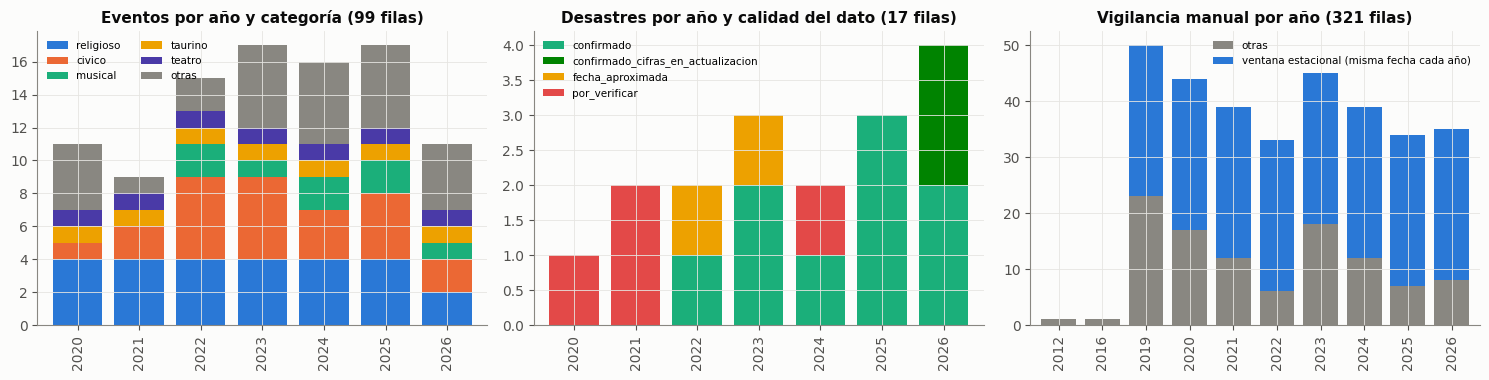

ventana_estacional: 216 de 321 (67%); con número de casos: 28
desastres por calidad: {'confirmado': 9, 'por_verificar': 4, 'fecha_aproximada': 2, 'confirmado_cifras_en_actualizacion': 2}


,eventos,desastres,vigilancia manual,total
fuente_url,,,,
(sin URL),0,0,117,117
ins.gov.co,0,0,80,80
ideam.gov.co,0,0,49,49
eltiempo.com,18,0,5,23
arquidiocesisdemanizales.com,23,0,0,23
minsalud.gov.co,1,0,14,15
infobae.com,4,2,5,11
centrodeinformacion.manizales.gov.co,3,4,4,11
paho.org,0,0,8,8


In [17]:
desastres = desastres.assign(calidad_dato=desastres.calidad_dato.where(~desastres.calidad_dato.str.startswith("pend"), "por_verificar"))
dom = lambda s: s.fillna("").map(lambda u: urlparse(u).netloc.replace("www.", "") or "(sin URL)")
ev_anio = eventos.assign(anio=pd.to_datetime(eventos.fecha_inicio).dt.year).dropna(subset=["anio"]).astype({"anio": int})
top_cat = ev_anio.categoria.value_counts().index[:5]
ev_anio["cat"] = ev_anio.categoria.where(ev_anio.categoria.isin(top_cat), "otras")
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
t1 = ev_anio.pivot_table(index="anio", columns="cat", values="nombre_evento", aggfunc="count").fillna(0)
t1[list(top_cat) + ["otras"]].plot.bar(stacked=True, ax=axes[0], color=[AZUL, NARANJA, AQUA, AMARILLO, VIOLETA, MUDO], width=.8)
axes[0].set_title(f"Eventos por año y categoría ({len(eventos)} filas)"); axes[0].legend(fontsize=7.5, ncol=2); axes[0].set_xlabel("")
d_anio = desastres.assign(anio=pd.to_datetime(desastres.fecha_inicio).dt.year)
t2 = d_anio.pivot_table(index="anio", columns="calidad_dato", values="tipo_evento", aggfunc="count").fillna(0)
t2.plot.bar(stacked=True, ax=axes[1], color=[AQUA, VERDE, AMARILLO, ROJO][:t2.shape[1]], width=.8)
axes[1].set_title(f"Desastres por año y calidad del dato ({len(desastres)} filas)"); axes[1].legend(fontsize=7.5); axes[1].set_xlabel("")
v_anio = vman.assign(anio=pd.to_datetime(vman.fecha_inicio).dt.year,
                     tipo=np.where(vman.estado.eq("ventana_estacional"), "ventana estacional (misma fecha cada año)", "otras"))
t3 = v_anio.pivot_table(index="anio", columns="tipo", values="nombre_evento", aggfunc="count").fillna(0)
t3.plot.bar(stacked=True, ax=axes[2], color=[MUDO, AZUL], width=.8)
axes[2].set_title(f"Vigilancia manual por año ({len(vman)} filas)"); axes[2].legend(fontsize=7.5); axes[2].set_xlabel("")
plt.tight_layout(); plt.show()
fu = pd.concat({"eventos": dom(eventos.fuente_url).value_counts(), "desastres": dom(desastres.fuente_url).value_counts(),
                "vigilancia manual": dom(vman.fuente_url).value_counts()}, axis=1).fillna(0).astype(int)
fu["total"] = fu.sum(axis=1)
print("ventana_estacional:", int((vman.estado == "ventana_estacional").sum()), "de", len(vman),
      f"({(vman.estado == 'ventana_estacional').mean():.0%}); con número de casos: {int(vman.casos.notna().sum())}")
print("desastres por calidad:", desastres.calidad_dato.value_counts().to_dict())
fu.sort_values("total", ascending=False).head(12)

## Lectura

- **Eventos (99 filas):** 9 a 17 por año, casi todos recurrentes anuales (religiosos 26, cívicos 22, musicales 10, feria 7, taurinos 7, teatro 7, literarios 7, deportivos 7). Las fuentes más citadas son la Arquidiócesis (23) y El Tiempo (18). **Tiene fechas, no intensidad**: no dice cuánta gente fue.
- **Desastres (17 filas):** 4 por verificar y 2 con fecha aproximada. Los sustituiría la UNGRD, que registra 80 emergencias de Manizales entre 2019 y 2025.
- **Vigilancia manual (321 filas):** 216 (67 %) son ventanas estacionales, las mismas fechas cada año. Solo 28 traen número de casos y 117 no tienen URL. **Es calendario disfrazado**; ya la sustituyen el SIVIGILA y el Power BI.

**Qué se encontró con ellos.**
- **La Feria de Manizales** sube el triage total **+6,3 % de media, pero de −7,7 % a +27,3 % según el año**; esa media depende de 2022, que cae en la ventana COVID, y sin ese año queda en +2,1 %. No se separa del regreso de vacaciones de enero (cuaderno 06). Contra otros 52 regresos de vacaciones, los días 0-4 de la Feria dan **SOAT +36,9 ± 5,5 % contra +12,5 ± 8,5 %** y particulares +61 % contra +29 %, mientras el total da +7,3 % contra +2,7 %, que se solapan (cuaderno 07): el efecto está en un subgrupo, no en el total.
- **El fútbol no tiene datos:** el calendario de eventos trae solo 2 partidos del Once Caldas (sección 8).

**Qué pueden sostener.** Marcar fechas conocidas, como la Feria o el terremoto.

**Qué no.** Medir intensidad, ni servir de variable de salud: sus ventanas las explica el mes del año (cuaderno 05).

## 7.3 Las fiestas de los municipios de Caldas

**Qué es.** Un calendario de las fiestas de 26 municipios de Caldas, 2020-2026, con 177 ediciones, 167 con URL; 119 fechas confirmadas y 58 estimadas; 130 filas verificadas abriendo la página, 8 vistas solo en el buscador y 39 inferidas (marca V, B e I). El estado de cada edición importa: en las canceladas o aplazadas, la fecha es la prevista, de modo que el análisis se restringe a las realizadas. La hipótesis que motiva el calendario es que lo que el hospital de un pueblo no puede atender termina en Manizales.

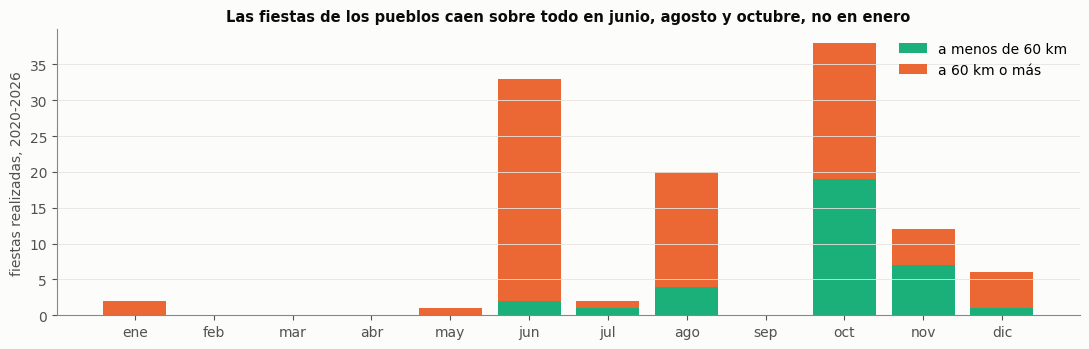

por estado: {'realizado': 116, 'cancelado': 27, 'programado': 6, 'virtual': 5, 'aplazado': 4} | municipios: 26 | filas con URL: 167 de 177
calidad de la fecha: {'confirmada': 119, 'estimada': 58} | marca: {'V': 130, 'I': 39, 'B': 8}
fiestas realizadas por mes: {1: 2, 2: 0, 3: 0, 4: 0, 5: 1, 6: 33, 7: 2, 8: 20, 9: 0, 10: 38, 11: 12, 12: 6}
recesos escolares oficiales: 29 filas, {'fin_de_anio': 12, 'mitad_de_anio': 6, 'octubre': 6, 'semana_santa': 5}


mes,1,2,3,4,5,6,7,8,9,10,11,12
lejana,,,,,,,,,,,,
a menos de 60 km,0,0,0,0,0,2,1,4,0,19,7,1
a 60 km o más,2,0,0,0,1,31,1,16,0,19,5,5


In [18]:
# Fiestas de los municipios de Caldas: cuándo caen y a qué distancia de Manizales.
fi = fiestas.assign(mes=fiestas.fecha_inicio.dt.month, lejana=fiestas.distancia_km_manizales >= 60)
real = fi[fi.estado == "realizado"]
tabf = real.groupby(["mes", "lejana"]).size().unstack(fill_value=0).reindex(range(1, 13), fill_value=0)
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(tabf.index, tabf.get(False, 0), color=AQUA, label="a menos de 60 km")
ax.bar(tabf.index, tabf.get(True, 0), bottom=tabf.get(False, 0), color=NARANJA, label="a 60 km o más")
ax.set_xticks(range(1, 13), ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"])
ax.set_ylabel("fiestas realizadas, 2020-2026"); ax.legend(); ax.grid(axis="x", visible=False)
ax.set_title("Las fiestas de los pueblos caen sobre todo en junio, agosto y octubre, no en enero", fontsize=10.5)
plt.tight_layout(); plt.show()
print("por estado:", fiestas.estado.value_counts().to_dict(), "| municipios:", fiestas.municipio.nunique(), "| filas con URL:", int(fiestas.fuente_url.notna().sum()), "de", len(fiestas))
print("calidad de la fecha:", fiestas.calidad_fecha.value_counts().to_dict(), "| marca:", fiestas.marca.value_counts().to_dict())
print("fiestas realizadas por mes:", tabf.sum(axis=1).astype(int).to_dict())
print("recesos escolares oficiales:", len(escolar), "filas,", escolar.tipo.value_counts().to_dict())
tabf.rename(columns={False: "a menos de 60 km", True: "a 60 km o más"}).T


## Lectura

- **Las fiestas realizadas caen en octubre (38), junio (33), agosto (20) y noviembre (12); en enero, solo 2** (el Carnaval de Riosucio, en años impares). De las 116 realizadas, 114 tienen fecha de inicio. Octubre y noviembre son justo los meses **sin** semanas altas de triage (0 %), y enero, el mes de más picos puntuales, casi no tiene fiestas de pueblo.
- Siete de cada diez fiestas realizadas (80 de 114) están a 60 km o más de Manizales.
- El terremoto del 10 de agosto de 2026 canceló o aplazó varias.

**Qué se encontró con ellas.** Durante la fiesta y los 3 días posteriores, el triage total sube **+1,9 % [+0,5; +3,4]** con las fiestas lejanas (60 km o más) y **+0,2 %** con las cercanas; en los 15-44 años, +2,1 % con las lejanas. Son 18 pruebas sobre 107 fiestas realizadas con fecha. La huella del asegurador no acompaña (particulares −7,5 %; IPS remitente −6 %, −10 % con las cercanas). El patrón «lejos mayor que cerca» encaja con la hipótesis de remisión, pero el efecto es pequeño (cuaderno 08).

**Límite.** Sin la serie de remisiones del CRUE (sección 8) la hipótesis no se puede probar de forma directa: solo se ve su huella indirecta en el triage del SES.

---
# 8. Calidad, hallazgos, fuentes identificadas, límites y conclusiones

## 8.1 Calidad: escalones y caídas de registro conocidos

Cada fila está medida en este cuaderno o en el documento citado.

| Fuente | Qué pasa | Fecha | Magnitud | Cómo se trata |
|---|---|---|---|---|
| Triage | Días sin filas y caída parcial | 2024-03-19 y 20; el 21 con 40 triages | caída del registro | nulo en el total; excluido por la regla del 40 % de lo esperado |
| 995 | Calidad baja | 2012-2014 | duplicados, semanas con 2 instituciones | la serie empieza en 2015 |
| 995 | El denominador crece por escalones | 2020→2021, 2023→2024 | +60 %, +35 % | proporción solo dentro del año; conteo entre años |
| 995 | El SES está en el denominador | 2015-2025 | 6,1-9,5 % | se excluye de «consultas de la ciudad» |
| 998 | Caída de la EDA y de las instituciones que notifican | desde 2020 | índice 100 → 42-43; instituciones 33,6 → ~21 | sin resolver |
| 998 | Semana errónea | SE53 de 2025 (2025-12-28) | 2.495 casos contra mediana semanal de 488 | se excluye |
| Eventos SIVIGILA | 831, 414 (y 365), 549, 113, 348, 155 | 2015-2023 | −92 %, −93 %, ×3, ×2,9, COVID, año sin publicar | mirar la serie; usar solo dentro de un régimen |
| Eventos SIVIGILA | La fecha que define la semana cambia | por evento y año | desplaza casos entre semanas | `casos_ocurrencia_semana_consulta` para el histórico |
| Power BI 995 | Nivel por encima de los microdatos | todos los años | IRA +3,4 a +7,9 % | factor por año, o proporción |
| Power BI 995 | Semana rota | SE52 de 2021 | 96 contra 814 | excluirla al empalmar |
| Power BI 995 | Sin 2020 | 2020 | — | microdatos para 2020 |
| Power BI 300 | Total por debajo | 2024 | −8,3 % | sin explicar |
| Clima | Pluviómetro en cero, antes marcado como dato bueno | 199 días, 2025-10-05 a 2026-07-08 | 0 mm contra 99-237 de NASA | `pluviometro_fallido`: se trata como sin pluviómetro |
| Clima | Nivel de toda la lluvia | 2020-2026 | +15 a +25 % por año al quitar la falla | efecto del factor de escala de NASA; no comparar niveles sin tratar con tratados |
| Clima | Sin ninguna medida en tierra | 2021 | 0 días de pluviómetro; 57 de METAR | tratar 2021 como reanálisis |
| Clima | Sin pluviómetro | 2020-08 a 2021-12; 2023-04 a 2024-06; y los 199 días en falla | — | NASA escalado; acumulados de 7 días |
| Clima | Mes al borde del umbral de falla | 2025-08 | 13 mm contra 119 de NASA, razón 0,111 | queda como dato; no se sabe si es falla |
| Clima | Estación Planalto y lluvia ERA5 | 2020-2023 | +7,4 °C; 16.555 mm/año | excluidos |
| Clima completo | Lluvia solo válida en ventanas largas | todo el periodo | NASA r = 0,28 por día, 0,66 por mes | ventanas de 7 días o más |
| MinDefensa | Pozo de registro en tránsito | 2018-2019 | 279 casos y 38 % de días con caso en 2019 | usar 2021 en adelante |
| MinDefensa | Lesiones personales | 2018→2025 | −62 % | no leerlo como realidad |
| MinDefensa | Violencia intrafamiliar | 2019; 2025 | 395 → 688; 760 → 475 | mirar la serie |
| Entidad | Triages sin entidad asociada | desde 2025-04 | 1,0-1,2 % | grupo aparte |
| Entidad | Escalones del reparto | 2021-12, 2024-04, 2025-11, 2026-07 | 9-22 puntos de cuota | son la red, no un error: variable explícita |
| BDUA | Sin histórico | siempre | solo la foto del mes | captura semanal desde 2026-10-02 |
| Supersalud | Solo medidas vigentes | siempre | las levantadas desaparecen | captura semanal; Sanitas discrepa entre portales |
| Calendario | Regreso a clases dentro de vacaciones | todos los años | 53 de 53 días | usar los recesos oficiales |
| Calendario | Festivo del 13-jul-2026 | 2026 | 19 festivos | verificar contra la norma |
| Manuales | Fechas fijas y filas sin verificar | 2012-2026 | 67 % ventanas; 4 desastres por verificar | reemplazar por fuentes oficiales |
| Fiestas de Caldas | Fecha estimada o fiesta no realizada | 2020-2026 | 58 fechas estimadas; 27 canceladas, 4 aplazadas, 5 virtuales y 6 programadas | filtrar por estado y calidad de la fecha |

## 8.2 Lo que se encontró con cada fuente

La tabla reúne, por fuente, los hallazgos medidos en otros cuadernos y los reproducidos aquí, con su cifra y su origen. Ninguno se calcula de nuevo en este cuaderno salvo los marcados «(aquí)».

| Fuente | Hallazgo | Cifra | Origen |
|---|---|---|---|
| Triage por entidad | El nivel del volumen lo mueve la red, no el calendario | Nueva EPS 115,8 → 72,2 triages por día entre 2025 y 2026 (−38 %) | cuaderno 07 |
| Triage por entidad | El escalón de abril de 2024 fue de Sura | Sura +40 por día; Nueva EPS −0,2 | cuaderno 18 |
| Afiliación MinSalud | La caída de Nueva EPS es de acceso, no de traslado | afiliados −19,5 %, triage −59,9 %, uso por afiliado −50,1 % (aquí) | cuaderno 18 y sección 5.1 |
| Supersalud | Las resoluciones de noviembre de 2025 coinciden con el desplome | resoluciones del 14 y el 25-nov-2025; escalón del 15-nov (aquí) | cuaderno 18 y sección 5.1 |
| SIVIGILA 995 | Frío y humedad anteceden a la IRA de la ciudad | temperatura media → IRA r = −0,37 a 4 semanas | cuaderno 09 |
| SIVIGILA 995 y clima completo | Un mes lluvioso y nublado trae más IRA | +6-7 % a 1-5 semanas; 53 de 266 pruebas sobreviven | cuaderno 17 |
| SIVIGILA 995 | La ola respiratoria llega diluida al triage total | +11-14 % en el respiratorio del hospital, menos de +2 % en el total | cuaderno 13 |
| SIVIGILA 998 | La EDA hospitalizada «anticipaba» el triage solo por estacionalidad compartida | +1,6 a +2,0 % → −0,3 / −0,5 % sin la estación | cuaderno 13 |
| Eventos SIVIGILA | La Niña sube violencias, salud mental y varicela | +0,35, +0,31 y +0,38 desviaciones típicas | cuaderno 20 |
| Power BI | La IRA operativa se puede calcular a tiempo | anomalía operativa r = 0,806 con la del cuaderno | cuaderno 13 |
| Clima unificado | La falla del pluviómetro fabricaba sequías y «rupturas» | seco → lluvioso en 0-4 años: +22,0 % con 13 episodios (sin tratar la falla) → +13,4 ± 15,0 % con 17, ya no distinguible de cero | cuaderno 07 y sección 3 |
| Clima completo | El entorno general no predice el triage total de forma estable | 693 pruebas, 84 con p < 0,05, 1 confirmada | cuaderno 12 |
| Clima completo | El clima mueve la IRA de la ciudad; sobre el total sus efectos son pequeños y no son los de la IRA diluida | 53 pruebas contra IRA; 36 contra el total con +1,5-2,4 %; 0 contra ingresos respiratorios; correlación −0,35 entre los efectos sobre la IRA y sobre el total | cuaderno 17 |
| MinDefensa | El calendario mueve la violencia de la ciudad | lesiones personales ×1,96 en noche festiva; ×1,78 en domingo | cuaderno 09 |
| MinDefensa | La noche festiva es violenta en la ciudad y distinta en el SES | +201 % el 1-ene en la ciudad; en el SES, día −40 % el 31 y madrugada +35 % el 1-ene | cuaderno 08 |
| MinDefensa | El tránsito de la ciudad no llega al SES | r = 0,01 con el SOAT del SES | cuaderno 07 |
| ENSO | El Niño calienta Manizales | r = +0,49 con la temperatura | cuaderno 09 |
| ENSO | El Niño se asocia con más triage, pero con un solo episodio | +3,6 % (p < 0,001), 1 episodio en la ventana del hospital | cuaderno 20 |
| Sismos USGS | Los sismos habituales no mueven la ciudad ni el hospital | 40 episodios de M 4,5 o más | cuaderno 20 |
| Desastres | El terremoto del 10-ago-2026 baja el triage registrado | Método semanal: −50 % el día, −26 % la primera semana, −7 % días 8-21; contra 8 semanas previas: −48,7 % el día 0, −22,3 % días 1-7, −4,6 % días 8-21 | cuadernos 06 y 20 |
| Calendario escolar | Las vacaciones oficiales están por encima del nivel del año | +3,5 a +9,3 %, media +6,5 % | cuaderno 08 |
| Calendario escolar | El receso baja la IRA y la varicela de la ciudad | r = −0,20 y −0,18 en la misma semana | cuaderno 09 |
| Calendario | El festivo se parte en noche y día posterior | 3-ene +14,0 %; madrugada del 8-dic +44 % | cuaderno 08 |
| Eventos | La Feria sube a un subgrupo, no al total | SOAT +36,9 ± 5,5 %; total +7,3 % contra +2,7 % | cuaderno 07 |
| Fiestas de Caldas | Las fiestas lejanas suben el total un poco | +1,9 % [+0,5; +3,4]; cercanas +0,2 % | cuaderno 08 |

## 8.3 Fuentes identificadas y no integradas

Se localizaron y se midieron las fuentes de la tabla, pero no se integraron al conjunto de variables. Las cifras son de la exploración documentada en `calendarios/docs/FUENTES_EXTERNAS.md`.

| Fuente | Qué cubre | Motivo por el que no se integró |
|---|---|---|
| UNGRD, consolidado de emergencias | 80 eventos de Manizales entre 2019 y 2025 (39 en 2019, 4 en 2025) | registro de emergencias reportadas para pedir apoyo, no un censo; 2026 sin publicar |
| Medicina Legal, lesiones de causa externa | lesiones no fatales preliminares desde enero de 2025; definitivas 2015-2024 | una fila por víctima con cuasi-identificadores, y granularidad de mes más día de la semana |
| Calidad del aire IDEAM (datos.gov.co) | PM10 diario de 1 día de cada 3 y PM2.5 horario; termina en diciembre de 2024 | no es una serie diaria continua y se detiene a fines de 2024 |
| Pronóstico archivado, Open-Meteo | temperatura pronosticada con antelación real desde 2021-03; lluvia desde 2024-01 | cubre solo unos 2,7 años de lluvia; es lo que se necesitaría para pronosticar con clima real |
| Google Mobility | 974 días, 2020-02-15 a 2022-10-15, serie cerrada | solo da contexto de la COVID |
| Aerocivil y Supertransporte | pasajeros mensuales por aire; terminal de buses diaria | sirven como tendencia; la terminal tiene 2024 con un solo día |
| DANE (población, desempleo, IPC) | población anual, GEIH trimestral móvil desde 2007, IPC mensual | controles lentos de tendencia |
| ACLED, protestas | mensual por municipio (Manizales 2021: 38) | por día solo con cuenta del proveedor |

## 8.4 Fuentes que no se pudieron obtener

Estas ausencias limitan lo que el análisis puede afirmar.

**Informes del CRUE (remisiones desde los municipios).** La Dirección Territorial de Salud de Caldas publica 119 informes mensuales de «Referencia y contrarreferencia» del CRUE, de enero de 2015 a agosto de 2026, pero cada descarga exige resolver un reCAPTCHA v2 y no se evadió. No se conoce su contenido: no hay certeza de que traigan remisiones por municipio de origen, por institución receptora o por día, y no solo totales. Sin ellos, el mecanismo «fiestas de los pueblos → remisiones → SES» solo se observa por su huella indirecta (+1,9 % con las fiestas lejanas), y la hipótesis de que en enero llegan pacientes que los hospitales de los pueblos no pudieron atender no se puede probar de forma directa.

**Partidos del Once Caldas.** El calendario de eventos solo tiene 2 partidos (Copa Sudamericana, 2025-03-05 y 2025-04-01). Existe una interfaz pública no documentada de ESPN con fecha, estadio y asistencia (23 partidos de local en 2025 en la liga), pero no se integró. Por eso el fútbol no puede analizarse como factor de pico, y cualquier ausencia de efecto del fútbol sería ausencia de dato.

**Calendario de contratación SES-EPS.** Las fechas de suspensión, reanudación y cambio de contrato entre el hospital y Nueva EPS no son públicas. Las resoluciones de la Supersalud explican el escalón de noviembre de 2025, pero marzo y julio de 2026 no tienen resolución cerca y son probablemente decisiones de contratación. Es el límite más pesado del inventario: la variable de mayor efecto sobre el nivel solo se observa después de ocurrir, y con esas fechas pasaría a ser un predictor conocido por adelantado.

**Otras ausencias.**
- **Alertas hospitalarias** (verde, amarilla, naranja, roja): no hay registro estructurado, solo comunicados sueltos de la Dirección Territorial de Salud, la Gobernación y la Alcaldía (23 publicaciones con «alerta hospitalaria» en el archivo de la Alcaldía, de 2021-12-23 a 2026-08-06).
- **Quejas por EPS (PQRD) de la Supersalud:** su página no expone enlaces de descarga y el reporte interactivo da 404. **Giros de ADRES:** tablero web sin verificar si se puede exportar.
- **Histórico de afiliación anterior a julio de 2025:** los zips antiguos no están enlazados en la página de MinSalud; un tablero público cubriría desde diciembre de 2016, según su manual, sin verificar.
- **Calidad del aire horaria de Manizales (CDIAC, Universidad Nacional y Corpocaldas):** el sitio está bloqueado por el filtro de la red institucional; sin ella no se mide la ceniza ni el PM10.
- **Cubos SISPRO/RIPS** (morbilidad por diagnóstico por municipio): exigen usuario y clave de MinSalud.
- **Pronóstico del clima:** el pronóstico archivado existe, pero sin integrarlo cualquier evaluación con clima observado mide algo que en operación no se tendrá.

## 8.5 Conclusiones y límites del análisis

**El inventario cubre las familias de factores que se buscaban, con una cobertura desigual.** Hay series largas y confiables para el calendario, el clima de reanálisis, el ENSO y los sismos; series con rezago de meses (SIVIGILA, 8 meses) o de semanas (MinDefensa, afiliación) y una vía casi en tiempo real para 2026 (Power BI, ~7 días); y listas escritas a mano para eventos, fiestas y desastres, que dan fechas pero no intensidad.

**Ninguna fuente se puede usar sin mirar primero su serie.** Casi todas tienen al menos un escalón de registro (el denominador del 995, la EDA, la mayoría de los eventos individuales, el tránsito de MinDefensa, el reparto por asegurador). El caso más grave fue el del pluviómetro de La Nubia, que reportó 199 días de ceros falsos y fabricó sequías que se parecían al mecanismo buscado; detectado y tratado, el efecto «seco → lluvioso» en los 0-4 años baja de +22,0 % a +13,4 ± 15,0 % y deja de distinguirse de cero. Un cambio de registro no se debe leer como un efecto.

**Cada familia de factores actúa en una capa distinta.** La red de aseguradores mueve el *nivel* del volumen (Nueva EPS, −38 % entre 2025 y 2026, y de acceso más que de traslado de afiliados). El calendario y los eventos mueven el *día a día* (la noche festiva, el día posterior, las vacaciones oficiales, la Feria en un subgrupo). El clima, la vigilancia y el ENSO actúan sobre la enfermedad transmisible de la ciudad y sobre el triage total con efectos de 1 a 3 %, que en el caso del clima no son los de la IRA diluida (cuaderno 17), mientras que sobre la fracción respiratoria del hospital el efecto es de 11 a 14 % y llega al total como un +2,2 % (cuaderno 13). Los barridos amplios sobre el total no confirman una variable de clima o de vigilancia como predictor firme; esto no prueba que esos factores no actúen, sino que un promedio sobre el total y sobre todo el periodo diluye efectos episódicos, de subgrupo o de condición.

**Límites.**
- Este cuaderno describe las fuentes; los efectos que cita se midieron en otros cuadernos y dependen de su diseño. Las cifras de clima anteriores al tratamiento de la falla del pluviómetro no son comparables con las actuales.
- El clima y la vigilancia del cuaderno son observaciones, no pronósticos: para operar se necesitarían el pronóstico archivado del clima y la vigilancia de Power BI con su historial de capturas, que apenas comienza (dos instantáneas), y la afiliación por EPS cubre solo 14 meses.
- Con los datos disponibles no se puede separar la caída de notificación de la caída real en la EDA, ni distinguir un mes seco de verdad del comienzo de la falla del pluviómetro en agosto de 2025.
- Las ausencias de la sección 8.4 (CRUE, partidos del Once Caldas y calendario de contratación SES-EPS) impiden probar la hipótesis de las remisiones, analizar el fútbol y conocer por adelantado el factor de mayor efecto sobre el nivel.